# Project 2: Housing Price Prediction – Pass 16

## Problem Definition


State the business problem. Translate the business problem into a Data Science problem by stating what kind of problem it is ( supervised vs unsupervised ) and whether it is a classification, regression, or clustering problem.

Statement:

We want to predict housing sale prices based on various correlated feature data. This is a *supervised regression* problem, where the target of the prediction is sales prices. To accomplish this, we use a regression model alongside Regression prediction techniques, as well as feature scaling and regularization to minimize the RMS percentage error.

## Data Collection/Sources


Data Collection describes the process by which we obtain the data for use in the project. In this case, our data comes from S3 storage buckets on AWS, which we load into memory (variables) via URLs by passing them to the read_csv function of the pandas python library (more on that soon).

The data comes in one large set containing the full data available for use in the project. It is supplemented by a data dictionary that describes the set, the data types of the included data, and other information relevant to its use.

Finally, to store the data in a form we can work with in memory, we use a storage structure called a DataFrame object from the pandas python library. This object allows us to quickly view the data and preview operations on the data without changing it, as well as make updates to the data in a highly intuitive way.

Load Pandas, Numpy, and Matplotlib modules

In [99]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm

from sklearn import datasets, metrics
from sklearn import model_selection
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import LabelEncoder

Load data Train.csv from AWS S3:

In [100]:
# url
url = 'https://ddc-datascience.s3.amazonaws.com/Projects/Project.2-Housing/Data/Housing.Data.csv'

Next, make a preview DataFrame to look at columns:

In [101]:
# make preview
df_preview = pd.read_csv(url)
df_preview

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000


In [102]:
# preview all column names
df_preview.columns

Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

Define the target column (and features types, if required):

In [103]:
# define target column (by name) and features column(s)
target_col = "SalePrice"
feature_types = ['float64', 'int64', 'O']

Create list of target col and feature cols:

In [104]:
# use list comprehension to generate list of target col + selected feature cols
selected_cols = [
    col
    for col in df_preview.columns
    if (col == target_col) or (df_preview[col].dtype in feature_types)
]
selected_cols

['PID',
 'MS SubClass',
 'MS Zoning',
 'Lot Frontage',
 'Lot Area',
 'Street',
 'Alley',
 'Lot Shape',
 'Land Contour',
 'Utilities',
 'Lot Config',
 'Land Slope',
 'Neighborhood',
 'Condition 1',
 'Condition 2',
 'Bldg Type',
 'House Style',
 'Overall Qual',
 'Overall Cond',
 'Year Built',
 'Year Remod/Add',
 'Roof Style',
 'Roof Matl',
 'Exterior 1st',
 'Exterior 2nd',
 'Mas Vnr Type',
 'Mas Vnr Area',
 'Exter Qual',
 'Exter Cond',
 'Foundation',
 'Bsmt Qual',
 'Bsmt Cond',
 'Bsmt Exposure',
 'BsmtFin Type 1',
 'BsmtFin SF 1',
 'BsmtFin Type 2',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Heating',
 'Heating QC',
 'Central Air',
 'Electrical',
 '1st Flr SF',
 '2nd Flr SF',
 'Low Qual Fin SF',
 'Gr Liv Area',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Full Bath',
 'Half Bath',
 'Bedroom AbvGr',
 'Kitchen AbvGr',
 'Kitchen Qual',
 'TotRms AbvGrd',
 'Functional',
 'Fireplaces',
 'Fireplace Qu',
 'Garage Type',
 'Garage Yr Blt',
 'Garage Finish',
 'Garage Cars',
 'Garage Area',
 'G

Read in the data from .csv using target_col and feature_types:

In [105]:
df_preview[selected_cols].dtypes.unique()

array([dtype('int64'), dtype('O'), dtype('float64')], dtype=object)

In [106]:
# make dataframe
df = pd.read_csv( url, usecols=selected_cols )

Finally, check the dataframe:

In [107]:
# check dataframe
df

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000


## Data Cleaning


Data Cleaning is the process of preparing the data set for use in analysis. Many data sets contain bad or null (empty) values, which can cause errors when trying to work with the data and use it in code. Cleaning the data involves removing bad (null-containing) columns and/or rows from the set, as well as imputing (replacing via insertion) similar data into fields with missing or unusable values.

Here, to clean the data, we mostly use the pandas drop function included with pandas DataFrame objects, which allow us to drop columns and rows according to conditions we specify, much like SQL WHERE clauses.

#### Examine the data using tools we have used in class. You should be identifying the various columns such as ...

    - target column
    - feature columns
    - identifier columns
    - null columns
    - null rows

    Tools you should be using include, but are not limited to:

    - head
    - tail
    - shape
    - size
    - info
    - describe
    - nunique
    - unique
    - isnull/isna



First, define the target column:

In [108]:
# check target_col
target_col

'SalePrice'

- head

In [109]:
# head
df.head()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,905101070,20,RL,62.0,14299,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2007,WD,Normal,115400
1,905101330,90,RL,72.0,10791,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Shed,500,10,2006,WD,Normal,90000
2,903454090,50,RM,50.0,9000,Pave,NaN,Reg,Bnk,AllPub,...,0,NaN,NaN,NaN,0,12,2007,WD,Normal,141000
3,533244030,60,FV,68.0,7379,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,254000
4,909252020,70,RL,60.0,7200,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,4,2009,WD,Normal,155000


- tail

In [110]:
# tail
df.tail()

,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
2632,903231070,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,Shed,400,9,2006,WD,Normal,114500
2633,906201021,80,RL,74.0,10778,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2009,WD,Normal,162000
2634,533253070,120,RL,61.0,3782,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2009,WD,Normal,211500
2635,527376100,20,RL,78.0,10140,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,8,2009,WD,Normal,165000
2636,528292060,60,RL,41.0,12460,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2008,WD,Normal,225000


- shape

In [111]:
# shape
df.shape

(2637, 81)

- size

In [112]:
# size
df.size

213597

- info

In [113]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 81 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   PID              2637 non-null   int64  
 1   MS SubClass      2637 non-null   int64  
 2   MS Zoning        2637 non-null   object 
 3   Lot Frontage     2188 non-null   float64
 4   Lot Area         2637 non-null   int64  
 5   Street           2637 non-null   object 
 6   Alley            180 non-null    object 
 7   Lot Shape        2637 non-null   object 
 8   Land Contour     2637 non-null   object 
 9   Utilities        2637 non-null   object 
 10  Lot Config       2637 non-null   object 
 11  Land Slope       2637 non-null   object 
 12  Neighborhood     2637 non-null   object 
 13  Condition 1      2637 non-null   object 
 14  Condition 2      2637 non-null   object 
 15  Bldg Type        2637 non-null   object 
 16  House Style      2637 non-null   object 
 17  Overall Qual  

- describe

In [114]:
# describe
df.describe()

,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,BsmtFin SF 1,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2.637000e+03,2637.000000,2188.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2614.000000,2636.000000,...,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000
mean,7.141301e+08,57.349261,69.166819,10044.694729,6.097459,5.569966,1971.288586,1984.202882,101.887911,438.441199,...,94.305271,46.984452,22.813424,2.368601,15.775123,2.130072,42.014031,6.243838,2007.795601,179986.230186
std,1.887527e+08,42.499091,23.356779,6742.549521,1.411522,1.118262,30.306986,20.913077,179.578232,449.602326,...,126.927272,66.564333,61.177638,23.160600,55.783751,35.140140,393.158781,2.722093,1.306403,78309.251522
min,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,5.284770e+08,20.000000,58.000000,7436.000000,5.000000,5.000000,1954.000000,1965.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,5.354530e+08,50.000000,68.000000,9450.000000,6.000000,5.000000,1973.000000,1993.000000,0.000000,368.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,9.071870e+08,70.000000,80.000000,11526.000000,7.000000,6.000000,2001.000000,2004.000000,164.000000,732.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213000.000000
max,1.007100e+09,190.000000,313.000000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,1424.000000,742.000000,584.000000,407.000000,576.000000,800.000000,12500.000000,12.000000,2010.000000,745000.000000


- nunique

In [115]:
# nunique
df.nunique().sort_values( ascending = False )

,0
PID,2637
Lot Area,1799
Gr Liv Area,1216
Bsmt Unf SF,1080
1st Flr SF,1022
...,...
Bsmt Half Bath,3
Paved Drive,3
Street,2
Alley,2


In [116]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
Bsmt Unf SF,40.955631
1st Flr SF,38.756162
...,...
Bsmt Half Bath,0.113766
Paved Drive,0.113766
Street,0.075844
Alley,0.075844


- unique

In [117]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [118]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
...,...
Mo Sold,0
Yr Sold,0
Sale Type,0
Sale Condition,0


In [119]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
...,...
Mo Sold,0.000000
Yr Sold,0.000000
Sale Type,0.000000
Sale Condition,0.000000


In [120]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([9.95828593e+01, 9.63594994e+01, 9.31740614e+01, 7.99772469e+01,
       6.09404626e+01, 4.86916951e+01, 1.70269245e+01, 5.57451650e+00,
       5.49867273e+00, 2.88206295e+00, 2.80621919e+00, 2.76829731e+00,
       8.72203261e-01, 7.58437619e-02, 3.79218809e-02, 0.00000000e+00])

In [121]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(14208)

In [122]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

2637

The target (SalePrice) contains no nulls, but the feature (Lot Frontage) contains about 17% null values. To address this, we can impute values using the median value in that column.

- dtypes

In [123]:
# dtypes
df.dtypes

,0
PID,int64
MS SubClass,int64
MS Zoning,object
Lot Frontage,float64
Lot Area,int64
...,...
Mo Sold,int64
Yr Sold,int64
Sale Type,object
Sale Condition,object


Examine null columns, columns with some nulls, and columns with no nulls:

In [124]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [125]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [126]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
Fireplace Qu,1284
Lot Frontage,449
Garage Cond,147
Garage Yr Blt,147
Garage Finish,147


In [127]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

26

In [128]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
PID,0
MS SubClass,0
MS Zoning,0
Lot Area,0
Street,0
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0


In [129]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

55

#### Target: Value Counts

In [130]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [131]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [132]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [133]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [134]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

In [135]:
df.shape, df.size

((2637, 81), 213597)

In [136]:
df.drop(columns = [target_col]).columns

Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

In [137]:
df.isna().any(axis=1).sum()

np.int64(2637)

In [138]:
df.columns

Index(['PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish'

#### Summary:

The dataset contains 2637 rows and 81 columns, making for a total of 213597 entries of data. Many of these fields are null.

Details:

  - target column: 'SalePrice'
  - feature columns: [
  'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Street',
       'Alley', 'Lot Shape', 'Land Contour', 'Utilities', 'Lot Config',
       'Land Slope', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type',
       'House Style', 'Overall Qual', 'Overall Cond', 'Year Built',
       'Year Remod/Add', 'Roof Style', 'Roof Matl', 'Exterior 1st',
       'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2',
       'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air',
       'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual',
       'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu',
       'Garage Type', 'Garage Yr Blt', 'Garage Finish', 'Garage Cars',
       'Garage Area', 'Garage Qual', 'Garage Cond', 'Paved Drive',
       'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch',
       'Screen Porch', 'Pool Area', 'Pool QC', 'Fence', 'Misc Feature',
       'Misc Val', 'Mo Sold', 'Yr Sold', 'Sale Type', 'Sale Condition'
  ]
  - identifier columns: 'PID'
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 2637 / 2637 (~100%)

Next, we split our data into three groups by data type in order to properly clean each group according to its particular needs.

In [139]:
# declare a df_all DataFrame for all the data
df_all = df.copy()

In [140]:
# Split df into three separate data frames --> df_float
df_float = df_all.drop( columns = [target_col] ).select_dtypes( include = ['float64'] )
df_float = pd.concat([pd.DataFrame(df[target_col]), df_float], axis = 1)
df_float.head()

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0


In [141]:
# Split df into three separate data frames --> df_int
df_int = df_all.drop( columns = [target_col] ).select_dtypes( include = ['int64'] )
df_int = pd.concat([pd.DataFrame(df[target_col]), df_int], axis = 1)
df_int.head()

,SalePrice,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,115400,905101070,20,14299,4,3,1964,1964,1005,0,...,0,0,0,0,0,0,0,0,7,2007
1,90000,905101330,90,10791,4,5,1967,1967,1296,0,...,0,0,0,0,0,0,0,500,10,2006
2,141000,903454090,50,9000,6,6,1937,1950,780,595,...,1,0,162,0,0,126,0,0,12,2007
3,254000,533244030,60,7379,8,5,2000,2000,975,873,...,1,280,184,0,0,0,0,0,4,2010
4,155000,909252020,70,7200,7,9,1936,2007,575,560,...,0,256,0,0,0,0,0,0,4,2009


In [142]:
# Split df into three separate data frames --> df_object
df_object = df_all.drop( columns = [target_col] ).select_dtypes( include = ['O'] )
df_object = pd.concat([pd.DataFrame(df[target_col]), df_object], axis = 1)
df_object.head()

,SalePrice,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
0,115400,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,Detchd,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal
1,90000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,CarPort,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal
2,141000,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,...,Detchd,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal
3,254000,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
4,155000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,...,Detchd,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal


#### Data Cleaning — Floats

In [143]:
# start by initializing df to df_float
df = df_float.copy()

- head

In [144]:
# head
df.head()

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0


- tail

In [145]:
# tail
df.tail()

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0
2636,225000,41.0,0.0,870.0,0.0,167.0,1037.0,0.0,0.0,1999.0,2.0,400.0


- shape

In [146]:
# shape
df.shape

(2637, 12)

- size

In [147]:
# size
df.size

31644

- info

In [148]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   SalePrice       2637 non-null   int64  
 1   Lot Frontage    2188 non-null   float64
 2   Mas Vnr Area    2614 non-null   float64
 3   BsmtFin SF 1    2636 non-null   float64
 4   BsmtFin SF 2    2636 non-null   float64
 5   Bsmt Unf SF     2636 non-null   float64
 6   Total Bsmt SF   2636 non-null   float64
 7   Bsmt Full Bath  2635 non-null   float64
 8   Bsmt Half Bath  2635 non-null   float64
 9   Garage Yr Blt   2490 non-null   float64
 10  Garage Cars     2636 non-null   float64
 11  Garage Area     2636 non-null   float64
dtypes: float64(11), int64(1)
memory usage: 247.3 KB


- describe

In [149]:
# describe
df.describe()

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
count,2637.000000,2188.000000,2614.000000,2636.000000,2636.000000,2636.000000,2636.000000,2635.000000,2635.000000,2490.000000,2636.000000,2636.000000
mean,179986.230186,69.166819,101.887911,438.441199,51.068665,555.669196,1045.179059,0.432258,0.058824,1978.185944,1.763278,470.968134
std,78309.251522,23.356779,179.578232,449.602326,172.521803,436.223188,429.686089,0.525239,0.240130,25.452647,0.760576,212.816905
min,12789.000000,21.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1895.000000,0.000000,0.000000
25%,129500.000000,58.000000,0.000000,0.000000,0.000000,218.000000,792.000000,0.000000,0.000000,1961.000000,1.000000,324.750000
50%,160000.000000,68.000000,0.000000,368.000000,0.000000,464.500000,988.000000,0.000000,0.000000,1979.000000,2.000000,480.000000
75%,213000.000000,80.000000,164.000000,732.000000,0.000000,797.250000,1290.250000,1.000000,0.000000,2002.000000,2.000000,576.000000
max,745000.000000,313.000000,1600.000000,5644.000000,1526.000000,2336.000000,6110.000000,3.000000,2.000000,2207.000000,5.000000,1488.000000


- nunique

In [150]:
# nunique
df.nunique().sort_values( ascending = False )

,0
Bsmt Unf SF,1080
Total Bsmt SF,1001
SalePrice,983
BsmtFin SF 1,935
Garage Area,576
Mas Vnr Area,425
BsmtFin SF 2,253
Lot Frontage,126
Garage Yr Blt,102
Garage Cars,6


In [151]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
Bsmt Unf SF,40.955631
Total Bsmt SF,37.959803
SalePrice,37.277209
BsmtFin SF 1,35.456959
Garage Area,21.843003
Mas Vnr Area,16.116799
BsmtFin SF 2,9.594236
Lot Frontage,4.778157
Garage Yr Blt,3.868032
Garage Cars,0.227531


- unique

In [152]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [153]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2
BsmtFin SF 1,1
Total Bsmt SF,1
BsmtFin SF 2,1
Garage Cars,1
Bsmt Unf SF,1


In [154]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Lot Frontage,17.026925
Garage Yr Blt,5.574516
Mas Vnr Area,0.872203
Bsmt Full Bath,0.075844
Bsmt Half Bath,0.075844
BsmtFin SF 1,0.037922
Total Bsmt SF,0.037922
BsmtFin SF 2,0.037922
Garage Cars,0.037922
Bsmt Unf SF,0.037922


In [155]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([17.02692454,  5.5745165 ,  0.87220326,  0.07584376,  0.03792188,
        0.        ])

In [156]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(629)

In [157]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

604

Many different null counts exist throughout the data set, indicating that this will not be a straightforward nulls cleanup.

- dtypes

In [158]:
# dtypes
df.dtypes

,0
SalePrice,int64
Lot Frontage,float64
Mas Vnr Area,float64
BsmtFin SF 1,float64
BsmtFin SF 2,float64
Bsmt Unf SF,float64
Total Bsmt SF,float64
Bsmt Full Bath,float64
Bsmt Half Bath,float64
Garage Yr Blt,float64


Examine null columns, columns with some nulls, and columns with no nulls:

In [159]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [160]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [161]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Half Bath,2
Bsmt Full Bath,2
BsmtFin SF 1,1
BsmtFin SF 2,1
Total Bsmt SF,1
Bsmt Unf SF,1
Garage Cars,1


In [162]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

11

In [163]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
SalePrice,0


In [164]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

1

#### Target: Value Counts

In [165]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [166]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [167]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [168]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [169]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

#### Summary:

The floats+ints-feature dataset contains 2637 rows and 38 columns, making for a total of 100206 entries of data. Many of these fields are null.

Details:

  - target column: 'SalePrice'
  - feature columns: [
       'Lot Frontage', 'Garage Yr Blt', 'Mas Vnr Area', 'Bsmt Full Bath',
       'Bsmt Half Bath', 'BsmtFin SF 2', 'BsmtFin SF 1', 'Total Bsmt SF',
       'Bsmt Unf SF', 'Garage Area', 'Garage Cars',
       'MS SubClass', 'Lot Area', 'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold'
       ]
  - identifier columns: 'PID'
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 2637 (100%)

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


First, make a backup:

In [170]:
# make backup
df_f_bak = df.copy()

In [171]:
# restore from backup
df = df_f_bak.copy()

In [172]:
# df again to double-check
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


1. Remove identifier columns

- No identifier columns

In [173]:
# backup 1
df_f_bak1 = df.copy()

In [174]:
# restore from backup 1
df = df_f_bak1.copy()

In [175]:
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


2. Drop null target rows



- No null target rows

3. Drop feature columns with many or all nulls

In [176]:
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2
BsmtFin SF 1,1
Total Bsmt SF,1
BsmtFin SF 2,1
Garage Cars,1
Bsmt Unf SF,1


In [177]:
# df = df.loc[:, df.isnull().mean() <= 0.5]
df = df.drop( columns = [index for index in list(df.isnull().sum().index) if (df.isnull().sum().loc[index] / df.shape[0] > 0.4)])

In [178]:
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [179]:
list(df.isnull().sum().index)

['SalePrice',
 'Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area']

In [180]:
df.shape

(2637, 12)

4. Drop remaining records with null counts (if few)

In [181]:
# backup 2
df_f_bak2 = df.copy()

In [182]:
# restore from backup 2
df = df_f_bak2.copy()

In [183]:
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [184]:
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,449
Garage Yr Blt,147
Mas Vnr Area,23
Bsmt Full Bath,2
Bsmt Half Bath,2
BsmtFin SF 1,1
Total Bsmt SF,1
BsmtFin SF 2,1
Garage Cars,1
Bsmt Unf SF,1


In [185]:
df = df.dropna(subset=[index for index in list(df.isnull().sum().index) if (df.isnull().sum().loc[index] / df.shape[0] < 0.05)])

In [186]:
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [187]:
list(df.isnull().sum().index)

['SalePrice',
 'Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area']

In [188]:
df.shape

(2611, 12)

5.  impute with the median for remaining fields

In [189]:
# backup 3
df_f_bak3 = df.copy()

In [190]:
# restore from backup 3
df = df_f_bak3.copy()

In [191]:
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [192]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Lot Frontage,443
Garage Yr Blt,145
Mas Vnr Area,0
SalePrice,0
BsmtFin SF 1,0
BsmtFin SF 2,0
Total Bsmt SF,0
Bsmt Unf SF,0
Bsmt Full Bath,0
Bsmt Half Bath,0


In [193]:
# normalize null counts (per column)
df.isnull().sum().sort_values( ascending = False ) / df.shape[0] * 100

,0
Lot Frontage,16.966679
Garage Yr Blt,5.553428
Mas Vnr Area,0.000000
SalePrice,0.000000
BsmtFin SF 1,0.000000
BsmtFin SF 2,0.000000
Total Bsmt SF,0.000000
Bsmt Unf SF,0.000000
Bsmt Full Bath,0.000000
Bsmt Half Bath,0.000000


Impute:

In [194]:
feature_cols = list(df.drop(columns = target_col).columns)
feature_cols

['Lot Frontage',
 'Mas Vnr Area',
 'BsmtFin SF 1',
 'BsmtFin SF 2',
 'Bsmt Unf SF',
 'Total Bsmt SF',
 'Bsmt Full Bath',
 'Bsmt Half Bath',
 'Garage Yr Blt',
 'Garage Cars',
 'Garage Area']

In [195]:
# loop through features to bulk impute with respective column medians
for feature_col in feature_cols:

  # Calculate the median
  median = df[feature_col].median()
  print(median)

  # Assign median to nulls
  df.fillna( {feature_col: median}, inplace = True )

  # Verify median is about the same as before
  print(df[feature_col].median())

68.0
68.0
0.0
0.0
368.0
368.0
0.0
0.0
463.0
463.0
988.0
988.0
0.0
0.0
0.0
0.0
1979.0
1979.0
2.0
2.0
478.0
478.0


In [196]:
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [197]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
SalePrice,0
Lot Frontage,0
Mas Vnr Area,0
BsmtFin SF 1,0
BsmtFin SF 2,0
Bsmt Unf SF,0
Total Bsmt SF,0
Bsmt Full Bath,0
Bsmt Half Bath,0
Garage Yr Blt,0


In [198]:
# backup 4
df_f_bak4 = df.copy()

In [199]:
# restore from backup 4
df = df_f_bak4.copy()

In [200]:
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,Garage Cars,Garage Area
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,2.0,440.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,2.0,516.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,1.0,544.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,2.0,592.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,2.0,576.0
...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,2.0,528.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,2.0,462.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,2.0,484.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,2.0,478.0


In [201]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

In [202]:
# backup
df_float_bak = df_float.copy()

In [203]:
# restore
df_float = df_float_bak.copy()

In [204]:
# update
df_float = df.copy()

#### Data Cleaning — Ints

In [205]:
# start by initializing df to df_int
df = df_int.copy()

- head

In [206]:
# head
df.head()

,SalePrice,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,115400,905101070,20,14299,4,3,1964,1964,1005,0,...,0,0,0,0,0,0,0,0,7,2007
1,90000,905101330,90,10791,4,5,1967,1967,1296,0,...,0,0,0,0,0,0,0,500,10,2006
2,141000,903454090,50,9000,6,6,1937,1950,780,595,...,1,0,162,0,0,126,0,0,12,2007
3,254000,533244030,60,7379,8,5,2000,2000,975,873,...,1,280,184,0,0,0,0,0,4,2010
4,155000,909252020,70,7200,7,9,1936,2007,575,560,...,0,256,0,0,0,0,0,0,4,2009


- tail

In [207]:
# tail
df.tail()

,SalePrice,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
2632,114500,903231070,50,6240,6,6,1934,1950,816,0,...,1,112,0,0,0,0,0,400,9,2006
2633,162000,906201021,80,10778,7,6,1990,1991,1061,0,...,0,114,36,0,0,0,0,0,7,2009
2634,211500,533253070,120,3782,8,5,1981,1981,1226,0,...,2,133,78,0,0,0,0,0,9,2009
2635,165000,527376100,20,10140,6,5,1974,1974,1350,0,...,1,0,0,0,0,0,0,0,8,2009
2636,225000,528292060,60,12460,7,5,1999,2000,1037,1285,...,1,144,44,0,0,0,0,0,5,2008


- shape

In [208]:
# shape
df.shape

(2637, 27)

- size

In [209]:
# size
df.size

71199

- info

In [210]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 27 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   SalePrice        2637 non-null   int64
 1   PID              2637 non-null   int64
 2   MS SubClass      2637 non-null   int64
 3   Lot Area         2637 non-null   int64
 4   Overall Qual     2637 non-null   int64
 5   Overall Cond     2637 non-null   int64
 6   Year Built       2637 non-null   int64
 7   Year Remod/Add   2637 non-null   int64
 8   1st Flr SF       2637 non-null   int64
 9   2nd Flr SF       2637 non-null   int64
 10  Low Qual Fin SF  2637 non-null   int64
 11  Gr Liv Area      2637 non-null   int64
 12  Full Bath        2637 non-null   int64
 13  Half Bath        2637 non-null   int64
 14  Bedroom AbvGr    2637 non-null   int64
 15  Kitchen AbvGr    2637 non-null   int64
 16  TotRms AbvGrd    2637 non-null   int64
 17  Fireplaces       2637 non-null   int64
 18  Wood Dec

- describe

In [211]:
# describe
df.describe()

,SalePrice,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
count,2637.000000,2.637000e+03,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,...,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000,2637.000000
mean,179986.230186,7.141301e+08,57.349261,10044.694729,6.097459,5.569966,1971.288586,1984.202882,1155.505878,337.004930,...,0.599166,94.305271,46.984452,22.813424,2.368601,15.775123,2.130072,42.014031,6.243838,2007.795601
std,78309.251522,1.887527e+08,42.499091,6742.549521,1.411522,1.118262,30.306986,20.913077,382.597499,427.742219,...,0.651052,126.927272,66.564333,61.177638,23.160600,55.783751,35.140140,393.158781,2.722093,1.306403
min,12789.000000,5.263011e+08,20.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,334.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000
25%,129500.000000,5.284770e+08,20.000000,7436.000000,5.000000,5.000000,1954.000000,1965.000000,878.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000
50%,160000.000000,5.354530e+08,50.000000,9450.000000,6.000000,5.000000,1973.000000,1993.000000,1082.000000,0.000000,...,1.000000,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000
75%,213000.000000,9.071870e+08,70.000000,11526.000000,7.000000,6.000000,2001.000000,2004.000000,1380.000000,708.000000,...,1.000000,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000
max,745000.000000,1.007100e+09,190.000000,164660.000000,10.000000,9.000000,2010.000000,2010.000000,4692.000000,2065.000000,...,4.000000,1424.000000,742.000000,584.000000,407.000000,576.000000,800.000000,12500.000000,12.000000,2010.000000


- nunique

In [212]:
# nunique
df.nunique().sort_values( ascending = False )

,0
PID,2637
Lot Area,1799
Gr Liv Area,1216
1st Flr SF,1022
SalePrice,983
2nd Flr SF,589
Wood Deck SF,367
Open Porch SF,238
Enclosed Porch,175
Year Built,118


In [213]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
PID,100.000000
Lot Area,68.221464
Gr Liv Area,46.113007
1st Flr SF,38.756162
SalePrice,37.277209
2nd Flr SF,22.335988
Wood Deck SF,13.917330
Open Porch SF,9.025408
Enclosed Porch,6.636329
Year Built,4.474782


- unique

In [214]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [215]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
SalePrice,0
PID,0
MS SubClass,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
1st Flr SF,0
2nd Flr SF,0


In [216]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
SalePrice,0.0
PID,0.0
MS SubClass,0.0
Lot Area,0.0
Overall Qual,0.0
Overall Cond,0.0
Year Built,0.0
Year Remod/Add,0.0
1st Flr SF,0.0
2nd Flr SF,0.0


In [217]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([0.])

In [218]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(0)

In [219]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

0

Many different null counts exist throughout the data set, indicating that this will not be a straightforward nulls cleanup.

- dtypes

In [220]:
# dtypes
df.dtypes

,0
SalePrice,int64
PID,int64
MS SubClass,int64
Lot Area,int64
Overall Qual,int64
Overall Cond,int64
Year Built,int64
Year Remod/Add,int64
1st Flr SF,int64
2nd Flr SF,int64


Examine null columns, columns with some nulls, and columns with no nulls:

In [221]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [222]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [223]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0


In [224]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

0

In [225]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
SalePrice,0
PID,0
MS SubClass,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
1st Flr SF,0
2nd Flr SF,0


In [226]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

27

#### Target: Value Counts

In [227]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [228]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [229]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [230]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [231]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

#### Summary:

The ints-feature dataset contains 2637 rows and 27 columns, making for a total of 71199 entries of data. Conveniently, none of these fields is null; as such, no columns or rows need to be removed, and no values need to be imputed.

Details:

  - target column: 'SalePrice'
  - feature columns: ['PID', 'MS SubClass', 'Lot Area', 'Overall Qual', 'Overall Cond',
       'Year Built', 'Year Remod/Add', '1st Flr SF', '2nd Flr SF',
       'Low Qual Fin SF', 'Gr Liv Area', 'Full Bath', 'Half Bath',
       'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd', 'Fireplaces',
       'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch',
       'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold']
  - identifier columns: 'PID'
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 0 (0%)

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


First, make a backup:

In [232]:
# make backup
df_i_bak = df.copy()

In [233]:
# restore from backup
df = df_i_bak.copy()

In [234]:
#df again to double-check
df

,SalePrice,PID,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,115400,905101070,20,14299,4,3,1964,1964,1005,0,...,0,0,0,0,0,0,0,0,7,2007
1,90000,905101330,90,10791,4,5,1967,1967,1296,0,...,0,0,0,0,0,0,0,500,10,2006
2,141000,903454090,50,9000,6,6,1937,1950,780,595,...,1,0,162,0,0,126,0,0,12,2007
3,254000,533244030,60,7379,8,5,2000,2000,975,873,...,1,280,184,0,0,0,0,0,4,2010
4,155000,909252020,70,7200,7,9,1936,2007,575,560,...,0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,903231070,50,6240,6,6,1934,1950,816,0,...,1,112,0,0,0,0,0,400,9,2006
2633,162000,906201021,80,10778,7,6,1990,1991,1061,0,...,0,114,36,0,0,0,0,0,7,2009
2634,211500,533253070,120,3782,8,5,1981,1981,1226,0,...,2,133,78,0,0,0,0,0,9,2009
2635,165000,527376100,20,10140,6,5,1974,1974,1350,0,...,1,0,0,0,0,0,0,0,8,2009


1. Remove identifier columns

In [235]:
# remove identifier columns from DataFrame
df = df.drop( columns = [ 'PID' ] )

In [236]:
# backup 2
df_i_bak2 = df.copy()

In [237]:
# restore from backup 2
df = df_i_bak2.copy()

In [238]:
df

,SalePrice,MS SubClass,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,1st Flr SF,2nd Flr SF,Low Qual Fin SF,...,Fireplaces,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold
0,115400,20,14299,4,3,1964,1964,1005,0,0,...,0,0,0,0,0,0,0,0,7,2007
1,90000,90,10791,4,5,1967,1967,1296,0,0,...,0,0,0,0,0,0,0,500,10,2006
2,141000,50,9000,6,6,1937,1950,780,595,0,...,1,0,162,0,0,126,0,0,12,2007
3,254000,60,7379,8,5,2000,2000,975,873,0,...,1,280,184,0,0,0,0,0,4,2010
4,155000,70,7200,7,9,1936,2007,575,560,0,...,0,256,0,0,0,0,0,0,4,2009
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,50,6240,6,6,1934,1950,816,0,360,...,1,112,0,0,0,0,0,400,9,2006
2633,162000,80,10778,7,6,1990,1991,1061,0,0,...,0,114,36,0,0,0,0,0,7,2009
2634,211500,120,3782,8,5,1981,1981,1226,0,0,...,2,133,78,0,0,0,0,0,9,2009
2635,165000,20,10140,6,5,1974,1974,1350,0,0,...,1,0,0,0,0,0,0,0,8,2009


2. Drop null target rows



- No null target rows

3. Drop feature columns with many or all nulls

- No columns with many or all nulls

4. Drop remaining records with null counts (if few)

- No remaining rows with null counts

5.  impute with the median for remaining fields

- No remaining fields are empty, so no imputations necessary

In [239]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
SalePrice,0
MS SubClass,0
Lot Area,0
Overall Qual,0
Overall Cond,0
Year Built,0
Year Remod/Add,0
1st Flr SF,0
2nd Flr SF,0
Low Qual Fin SF,0


In [240]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

In [241]:
# backup
df_int_bak = df_int.copy()

In [242]:
# restore
df_int = df_int_bak.copy()

In [243]:
# update
df_int = df.copy()

#### Data Cleaning — Objects

In [244]:
# start by initializing df to df_object
df = df_object.copy()

- head

In [245]:
# head
df.head()

,SalePrice,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
0,115400,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,Detchd,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal
1,90000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,CarPort,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal
2,141000,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,...,Detchd,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal
3,254000,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
4,155000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,...,Detchd,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal


- tail

In [246]:
# tail
df.tail()

,SalePrice,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
2632,114500,RM,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,...,Detchd,Unf,TA,TA,Y,NaN,MnPrv,Shed,WD,Normal
2633,162000,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,...,Attchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2634,211500,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,...,Attchd,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2635,165000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,Attchd,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal
2636,225000,RL,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,Gilbert,...,BuiltIn,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal


- shape

In [247]:
# shape
df.shape

(2637, 44)

- size

In [248]:
# size
df.size

116028

- info

In [249]:
# info
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2637 entries, 0 to 2636
Data columns (total 44 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   SalePrice       2637 non-null   int64 
 1   MS Zoning       2637 non-null   object
 2   Street          2637 non-null   object
 3   Alley           180 non-null    object
 4   Lot Shape       2637 non-null   object
 5   Land Contour    2637 non-null   object
 6   Utilities       2637 non-null   object
 7   Lot Config      2637 non-null   object
 8   Land Slope      2637 non-null   object
 9   Neighborhood    2637 non-null   object
 10  Condition 1     2637 non-null   object
 11  Condition 2     2637 non-null   object
 12  Bldg Type       2637 non-null   object
 13  House Style     2637 non-null   object
 14  Roof Style      2637 non-null   object
 15  Roof Matl       2637 non-null   object
 16  Exterior 1st    2637 non-null   object
 17  Exterior 2nd    2637 non-null   object
 18  Mas Vnr 

- describe

In [250]:
# describe
df.describe()

,SalePrice
count,2637.000000
mean,179986.230186
std,78309.251522
min,12789.000000
25%,129500.000000
50%,160000.000000
75%,213000.000000
max,745000.000000


- nunique

In [251]:
# nunique
df.nunique().sort_values( ascending = False )

,0
SalePrice,983
Neighborhood,28
Exterior 2nd,17
Exterior 1st,16
Sale Type,10
Condition 1,9
House Style,8
Functional,8
Roof Matl,8
Condition 2,8


In [252]:
# normalize to look for ID column(s)
df.nunique().sort_values( ascending = False ) / df.shape[0] * 100

,0
SalePrice,37.277209
Neighborhood,1.061813
Exterior 2nd,0.644672
Exterior 1st,0.606750
Sale Type,0.379219
Condition 1,0.341297
House Style,0.303375
Functional,0.303375
Roof Matl,0.303375
Condition 2,0.303375


- unique

In [253]:
# unique
df[target_col].unique()

array([115400,  90000, 141000, 254000, 155000, 125000, 194500, 185000,
       235000, 152000, 201000, 207000, 192000, 174000, 190000, 176000,
       384500, 395039, 167000, 165000, 195000, 104500, 161000, 245700,
       226001, 153500, 139000,  35000, 181000, 212000, 156000, 139500,
       225000,  12789, 157500, 110000, 130000, 263000, 205000, 117000,
       200624, 120000, 137900, 245500, 107000, 327000,  93000, 145250,
       168000, 169900, 122000, 161750, 188000, 149500, 421250, 305000,
        50138, 136000, 150750, 307000, 241000,  86900, 202500,  93500,
       121000, 107500, 336000, 213000, 129000, 170000, 337500, 535000,
       173500, 162000,  37900, 158500,  94000, 350000, 140000, 409900,
       115000, 177000,  94750, 121600, 128500, 301000, 230000, 151000,
       137500,  85500, 129400, 191500, 250000, 135000, 119000, 150000,
       178000, 163900, 199000, 203000, 178900, 180000, 182000, 177900,
       122500, 134900, 132000, 147983,  68500, 158000, 260261,  64500,
      

- isnull

In [254]:
# isnull
df.isnull().sum().sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
Fireplace Qu,1284
Garage Cond,147
Garage Finish,147
Garage Qual,147
Garage Type,145


In [255]:
# percent null by column
(df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100

,0
Pool QC,99.582859
Misc Feature,96.359499
Alley,93.174061
Fence,79.977247
Mas Vnr Type,60.940463
Fireplace Qu,48.691695
Garage Cond,5.574516
Garage Finish,5.574516
Garage Qual,5.574516
Garage Type,5.498673


In [256]:
# look at unique values in the col-by-col null counts to classify cols
((df.isnull().sum() / df.shape[0]).sort_values( ascending = False ) * 100).unique()

array([99.58285931, 96.35949943, 93.17406143, 79.97724687, 60.94046265,
       48.69169511,  5.5745165 ,  5.49867273,  2.88206295,  2.80621919,
        2.76829731,  0.        ])

In [257]:
# check to see if anything is not zero -- should return 0 if no nulls
df.isnull().sum().sum()

np.int64(13579)

In [258]:
# how many rows with at least one null
num_rows_with_nulls = df.isna().any(axis=1).sum()
int(num_rows_with_nulls)

2637

The target (SalePrice) contains no nulls, but the feature (Lot Frontage) contains about 17% null values. To address this, we can impute values using the median value in that column.

- dtypes

In [259]:
# dtypes
df.dtypes

,0
SalePrice,int64
MS Zoning,object
Street,object
Alley,object
Lot Shape,object
Land Contour,object
Utilities,object
Lot Config,object
Land Slope,object
Neighborhood,object


Examine null columns, columns with some nulls, and columns with no nulls:

In [260]:
# display columns with all null values
df.isnull().sum()[df.isnull().sum() == df.shape[0]]

,0


In [261]:
# count these
int(df.isnull().sum()[df.isnull().sum() == df.shape[0]].count())

0

In [262]:
# show columns with some null values
df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].sort_values( ascending = False )

,0
Pool QC,2626
Misc Feature,2541
Alley,2457
Fence,2109
Mas Vnr Type,1607
Fireplace Qu,1284
Garage Finish,147
Garage Cond,147
Garage Qual,147
Garage Type,145


In [263]:
# count these
int(df.isnull().sum()[(df.isnull().sum() != df.shape[0]) & (df.isnull().sum() != 0)].count())

15

In [264]:
# columns with no nulls
df.isnull().sum()[df.isnull().sum() == 0]

,0
SalePrice,0
MS Zoning,0
Street,0
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0
Neighborhood,0
Condition 1,0


In [265]:
# count these
int(df.isnull().sum()[df.isnull().sum() == 0].count())

29

#### Target: Value Counts

In [266]:
# value counts on target
df[target_col].value_counts( dropna = False )

,count
SalePrice,
140000,31
135000,30
130000,28
155000,24
160000,22
...,...
160200,1
174190,1
415298,1


In [267]:
# value counts normalized
df[target_col].value_counts( dropna = False, normalize = True ) * 100

,proportion
SalePrice,
140000,1.175578
135000,1.137656
130000,1.061813
155000,0.910125
160000,0.834281
...,...
160200,0.037922
174190,0.037922
415298,0.037922


In [268]:
# target col size/shape
df[[target_col]].shape[0]

2637

In [269]:
# sum of nulls in target
int(df[[target_col]].isnull().sum().iloc[0])

0

In [270]:
# sum of non-nulls in target
df[[target_col]].shape[0] - int(df[[target_col]].isnull().sum().iloc[0])

2637

There are no nulls in the target column, which means no rows will need to be dropped on its account.

In [271]:
df.shape, df.size

((2637, 44), 116028)

In [272]:
df.drop(columns = [target_col]).columns

Index(['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC',
       'Central Air', 'Electrical', 'Kitchen Qual', 'Functional',
       'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual',
       'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature',
       'Sale Type', 'Sale Condition'],
      dtype='object')

In [273]:
df.isna().any(axis=1).sum()

np.int64(2637)

#### Summary:

This abridged dataset contains 2637 rows and 44 columns, making for a total of 116028 entries of data. Many of these fields are null.

Details:

  - target column: 'SalePrice'
  - feature columns: [
  'MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual',
       'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC',
       'Central Air', 'Electrical', 'Kitchen Qual', 'Functional',
       'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Qual',
       'Garage Cond', 'Paved Drive', 'Pool QC', 'Fence', 'Misc Feature',
       'Sale Type', 'Sale Condition'
  ]
  - identifier columns: n/a
  - null columns: 0
  - null rows (target): 0
  - null rows (any): 2637 / 2637 (~100%)

#### If there are data cleaning issues, develop recommendations for how to deal with them.  Specifically, handle these common issues:

    - identifer columns
    - target column with null counts
    - feature columns with high null counts
    - feature columns with low null counts
    - feature columns with medium null counts


In [274]:
# head again to double-check
df.head()

,SalePrice,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
0,115400,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,Detchd,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal
1,90000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,CarPort,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal
2,141000,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,...,Detchd,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal
3,254000,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
4,155000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,...,Detchd,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal


In [275]:
# make backup
df_o_bak = df.copy()

In [276]:
# restore from backup
df = df_o_bak.copy()

In [277]:
df

,SalePrice,MS Zoning,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,...,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Pool QC,Fence,Misc Feature,Sale Type,Sale Condition
0,115400,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,Detchd,Unf,TA,TA,N,NaN,MnPrv,NaN,WD,Normal
1,90000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,CarPort,Unf,TA,TA,Y,NaN,NaN,Shed,WD,Normal
2,141000,RM,Pave,NaN,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,...,Detchd,Unf,TA,TA,P,NaN,NaN,NaN,WD,Normal
3,254000,FV,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Somerst,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
4,155000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,SWISU,...,Detchd,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,RM,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,...,Detchd,Unf,TA,TA,Y,NaN,MnPrv,Shed,WD,Normal
2633,162000,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,...,Attchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2634,211500,RL,Pave,NaN,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,...,Attchd,Fin,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2635,165000,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,...,Attchd,RFn,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal


In [278]:
# Setup drop thresholds

# Drop a column if null % above 85%
drop_column_threshold = 0.85

# Drop a row if null % below 15%
drop_row_threshold = 0.15

1. Remove identifier columns

- No identifier rows present in set (culled at read level)

2. Drop null target rows



- No null target rows

3. Drop feature columns with many or all nulls

In [279]:
# Select columns where the missing value ratio is less than drop_column_threshold
high_nulls = df.columns[df.isnull().mean() > drop_column_threshold]
high_nulls

Index(['Alley', 'Pool QC', 'Misc Feature'], dtype='object')

In [280]:
# Drop those specific columns
df = df.drop(columns=high_nulls)
df

,SalePrice,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Functional,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition
0,115400,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Typ,NaN,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal
1,90000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Typ,NaN,CarPort,Unf,TA,TA,Y,NaN,WD,Normal
2,141000,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,P,NaN,WD,Normal
3,254000,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,NaN,WD,Normal
4,155000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,Typ,NaN,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal
2633,162000,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Typ,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal
2634,211500,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Typ,TA,Attchd,Fin,TA,TA,Y,NaN,WD,Normal
2635,165000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal


4. Drop remaining records with null counts (if few)

In [281]:
# backup 2
df_o_bak2 = df.copy()

In [282]:
# restore from backup 2
df = df_o_bak2.copy()

In [283]:
df

,SalePrice,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Functional,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition
0,115400,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Typ,NaN,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal
1,90000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Norm,...,Typ,NaN,CarPort,Unf,TA,TA,Y,NaN,WD,Normal
2,141000,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,P,NaN,WD,Normal
3,254000,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,NaN,WD,Normal
4,155000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,Typ,NaN,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal
2633,162000,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Typ,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal
2634,211500,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Typ,TA,Attchd,Fin,TA,TA,Y,NaN,WD,Normal
2635,165000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal


In [284]:
# Select columns where the missing value ratio is less than drop_column_threshold
low_nulls = df.columns[df.isnull().mean() < drop_row_threshold]
low_nulls

Index(['SalePrice', 'MS Zoning', 'Street', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Exter Qual', 'Exter Cond',
       'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure',
       'BsmtFin Type 1', 'BsmtFin Type 2', 'Heating', 'Heating QC',
       'Central Air', 'Electrical', 'Kitchen Qual', 'Functional',
       'Garage Type', 'Garage Finish', 'Garage Qual', 'Garage Cond',
       'Paved Drive', 'Sale Type', 'Sale Condition'],
      dtype='object')

In [285]:
# Drop those specific columns
df = df.dropna(subset=low_nulls)
df

,SalePrice,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Functional,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition
0,115400,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Typ,NaN,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal
2,141000,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,P,NaN,WD,Normal
3,254000,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,NaN,WD,Normal
4,155000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,Typ,NaN,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal
5,125000,RL,Pave,Reg,Lvl,AllPub,FR2,Gtl,Sawyer,Feedr,...,Typ,Fa,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal
2633,162000,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Typ,NaN,Attchd,Unf,TA,TA,Y,NaN,WD,Normal
2634,211500,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Typ,TA,Attchd,Fin,TA,TA,Y,NaN,WD,Normal
2635,165000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal


5.  Impute with the median for remaining fields

In [286]:
# backup 3
df_o_bak3 = df.copy()

In [287]:
# restore from backup 3
df = df_o_bak3.copy()

In [288]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
Fence,1937
Mas Vnr Type,1420
Fireplace Qu,1108
MS Zoning,0
Land Contour,0
Utilities,0
Street,0
Lot Shape,0
SalePrice,0
Neighborhood,0


Impute:

In [289]:
# Get list of feature cols
feature_cols = list(df.drop(columns = target_col).columns)

# Loop through feature cols to bulk impute
for feature_col in feature_cols:

  # Assign mode to nulls
  mode = df[feature_col].mode(dropna = True)[0]
  df.fillna( {feature_col: mode}, inplace = True )

In [290]:
# check again how many of each column is null
df.isnull().sum().sort_values( ascending = False )

,0
SalePrice,0
MS Zoning,0
Street,0
Lot Shape,0
Land Contour,0
Utilities,0
Lot Config,0
Land Slope,0
Neighborhood,0
Condition 1,0


In [291]:
# check total null counts sum
f"Number of remaining nulls in df: {int(df.isnull().sum().sum())}"

'Number of remaining nulls in df: 0'

In [292]:
# backup
df_object_bak = df_object.copy()

In [293]:
# restore
df_object = df_object_bak.copy()

In [294]:
# update
df_object = df.copy()

## Exploratory Data Analysis


### EDA — Float

In [295]:
# set df to df_float
df = df_float.copy()

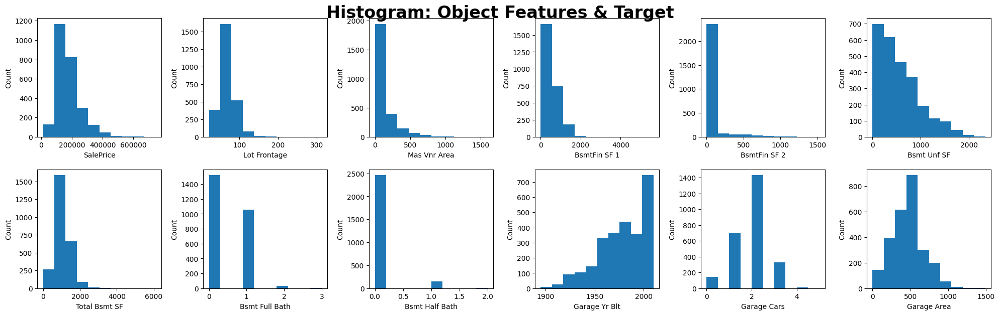

In [296]:
# Plot SalePrice and all of our predictors (features)

# parameterize plot settings
num_cols = 6
num_features = len(df.columns)
num_rows = num_features // num_cols + 1
plot_width = 20
plot_height = 3 * num_rows
column_names = df.columns
hist_y_label = "Count"

# assemble subplot canvas (subplots array)
fig, axs = plt.subplots(num_rows ,num_cols, figsize=(plot_width, plot_height))

# fill subplots
subplots = axs.flatten()
for n, column_name in enumerate(column_names): # Loop through rows
    subplots[n].hist(df[column_name])
    subplots[n].set_xlabel(column_name)
    subplots[n].set_ylabel(hist_y_label)

# hide empty subplots
for i in range(num_features, len(subplots)):
    fig.delaxes(subplots[i])

# format and show
plt.suptitle("Histogram: Object Features & Target", fontsize=24, weight="bold")
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

### What do we notice?

- SalePrice and Lot Frontage are positively skewed
- All float features look positively skewed
- Some features appear categorical (only a few unique values per feature)
- Perhaps some outliers

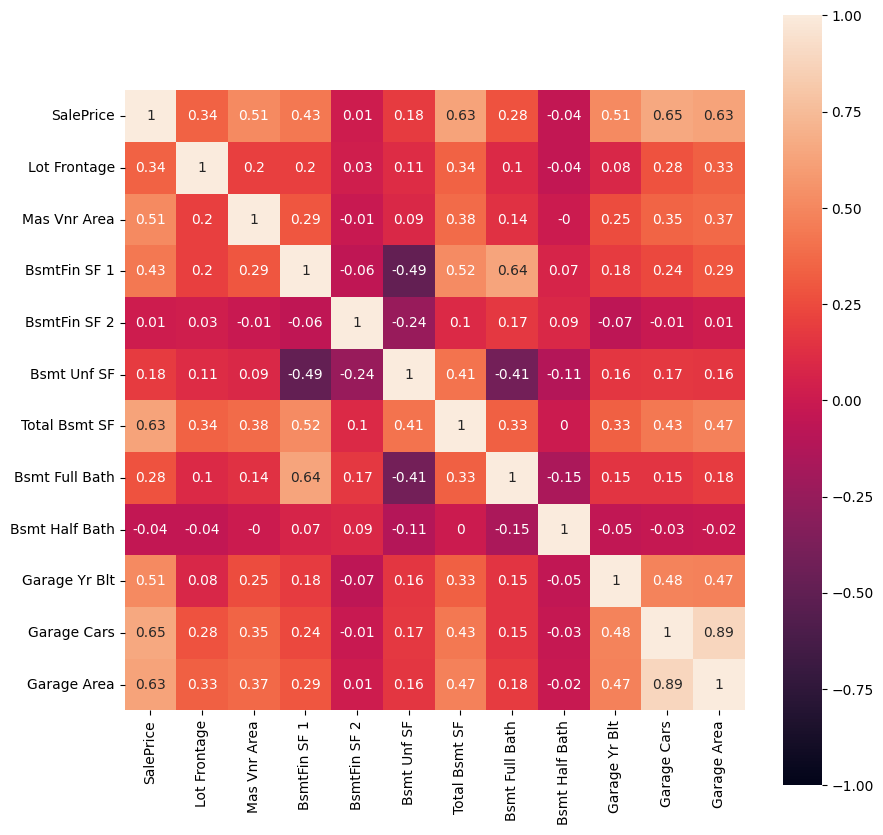

In [297]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=-1, vmax=1, square=True) ;



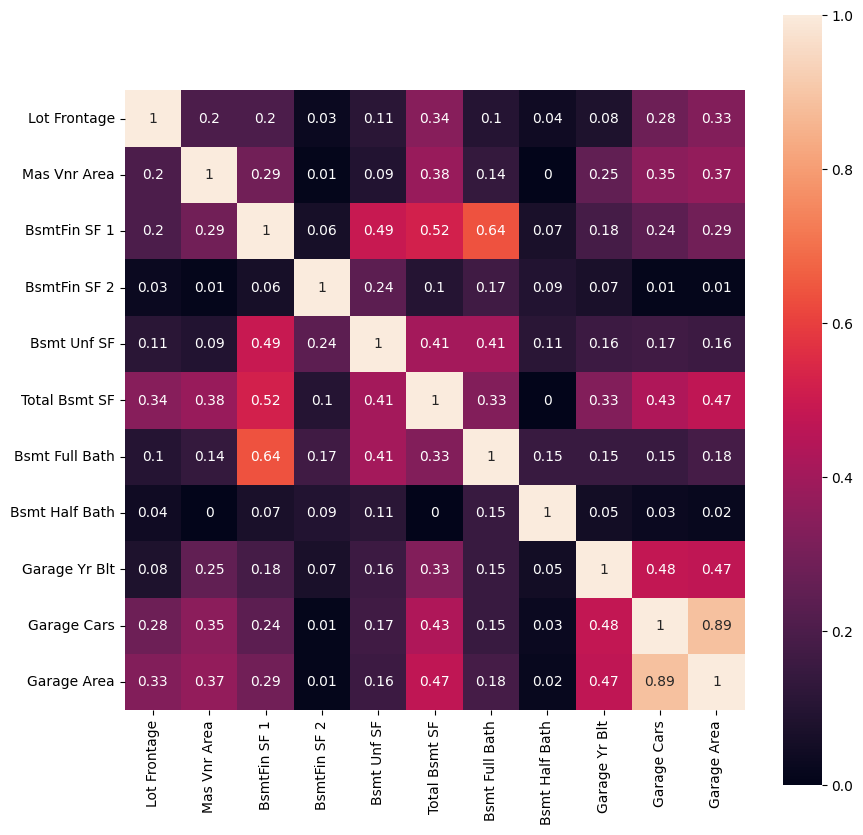

In [298]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = df.drop( columns = [target_col] ).corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=True, vmin=0, vmax=1, square=True) ;



In [299]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Garage Cars,0.65
Total Bsmt SF,0.63
Garage Area,0.63
Mas Vnr Area,0.51
Garage Yr Blt,0.51
BsmtFin SF 1,0.43
Lot Frontage,0.34
Bsmt Full Bath,0.28
Bsmt Unf SF,0.18


<Axes: >

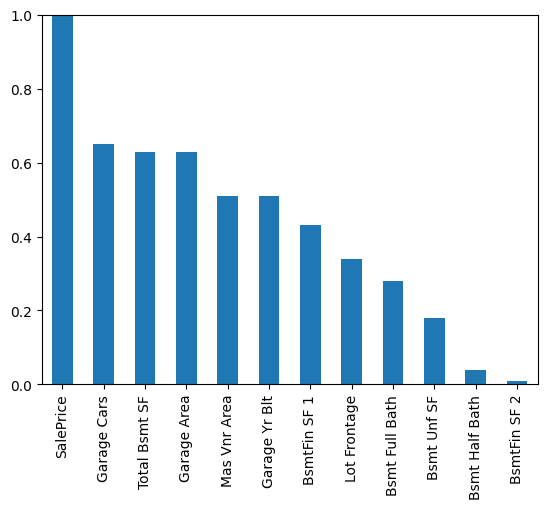

In [300]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [301]:
corrs_float = df.corr().round(2).unstack().abs()
corrs_float.reset_index()

,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,Lot Frontage,0.34
2,SalePrice,Mas Vnr Area,0.51
3,SalePrice,BsmtFin SF 1,0.43
4,SalePrice,BsmtFin SF 2,0.01
...,...,...,...
139,Garage Area,Bsmt Full Bath,0.18
140,Garage Area,Bsmt Half Bath,0.02
141,Garage Area,Garage Yr Blt,0.47
142,Garage Area,Garage Cars,0.89


In [302]:
corrs_float = corrs_float[corrs_float < 1]
corrs_float.reset_index()

,level_0,level_1,0
0,SalePrice,Lot Frontage,0.34
1,SalePrice,Mas Vnr Area,0.51
2,SalePrice,BsmtFin SF 1,0.43
3,SalePrice,BsmtFin SF 2,0.01
4,SalePrice,Bsmt Unf SF,0.18
...,...,...,...
127,Garage Area,Total Bsmt SF,0.47
128,Garage Area,Bsmt Full Bath,0.18
129,Garage Area,Bsmt Half Bath,0.02
130,Garage Area,Garage Yr Blt,0.47


In [303]:
corrs_float.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Garage Cars,Garage Area,0.89
1,Garage Area,Garage Cars,0.89
2,Garage Cars,SalePrice,0.65
3,SalePrice,Garage Cars,0.65
4,Bsmt Full Bath,BsmtFin SF 1,0.64
...,...,...,...
127,Garage Cars,BsmtFin SF 2,0.01
128,Mas Vnr Area,Bsmt Half Bath,0.00
129,Bsmt Half Bath,Total Bsmt SF,0.00
130,Total Bsmt SF,Bsmt Half Bath,0.00


In [304]:
corrs_float.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Garage Cars,Garage Area,0.89
1,Garage Cars,SalePrice,0.65
2,Bsmt Full Bath,BsmtFin SF 1,0.64
3,SalePrice,Garage Area,0.63
4,Total Bsmt SF,SalePrice,0.63
...,...,...,...
61,Mas Vnr Area,BsmtFin SF 2,0.01
62,Garage Area,BsmtFin SF 2,0.01
63,BsmtFin SF 2,Mas Vnr Area,0.01
64,Mas Vnr Area,Bsmt Half Bath,0.00


### What do we notice?

- SalePrice vs. Lot Frontage do not appear to be highly correlated to each other
- BsmtFin SF 2 and Bsmt Half Bath are very independent from most other features, but also poorly coorelate with SalePrice
- Garage Area and Garage Cars coorelate with target well and each other fairly well, but don't correlate with other features nearly as much, meaning one of these could be a good candidate

In [305]:
df.size

31332

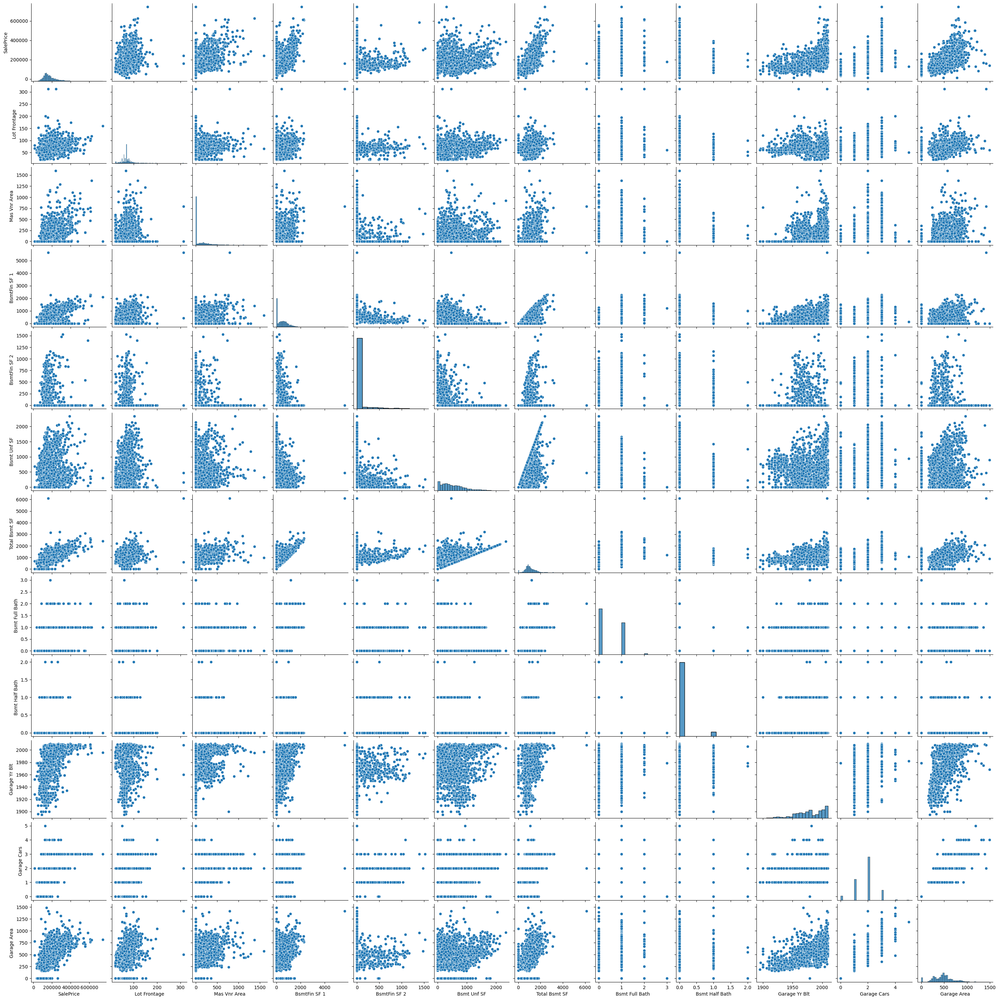

In [306]:
# Let's plot a pairplot
sns.pairplot(df) ;



### What do we notice?

- SalePrice vs. Lot Frontage is rather scattered, and does not appear to be linear.
- Many scattered relationships, some with some degree of potential linearity

In [307]:
# backup
df_float_bak2 = df_float.copy()

In [308]:
# restore
df_float = df_float_bak2.copy()

In [309]:
# update
df_float = df.copy()

### EDA — Int

In [310]:
# set df to df_int
df = df_int.copy()

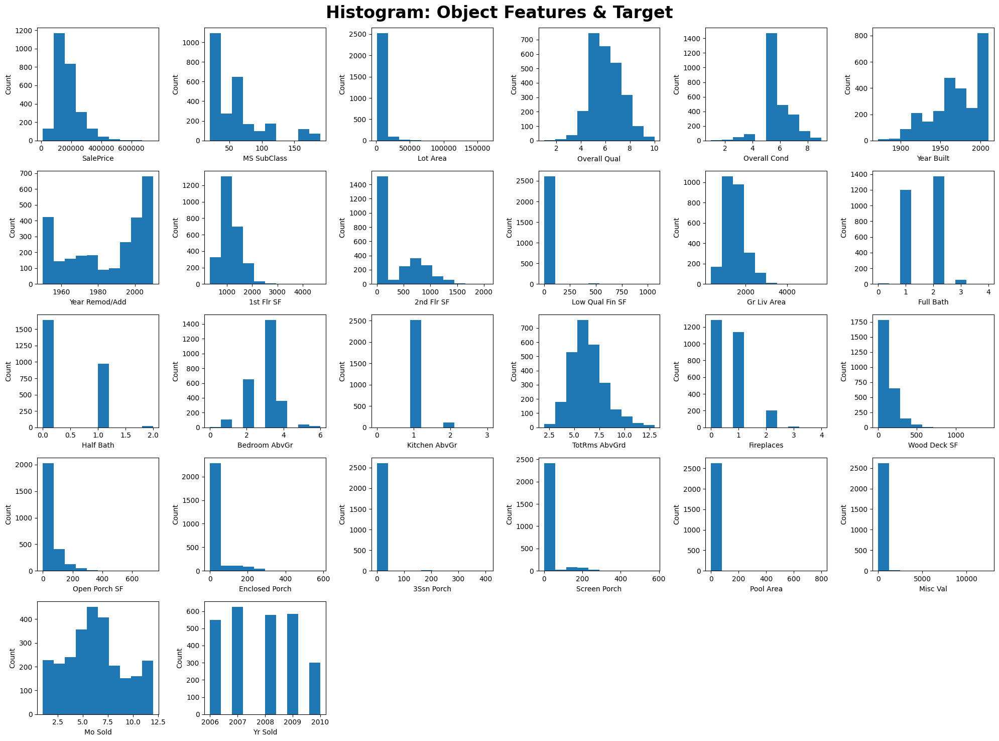

In [311]:
# Plot SalePrice and all of our predictors (features)

# parameterize plot settings
num_cols = 6
num_features = len(df.columns)
num_rows = num_features // num_cols + 1
plot_width = 20
plot_height = 3 * num_rows
column_names = df.columns
hist_y_label = "Count"

# assemble subplot canvas (subplots array)
fig, axs = plt.subplots(num_rows ,num_cols, figsize=(plot_width, plot_height))

# fill subplots
subplots = axs.flatten()
for n, column_name in enumerate(column_names): # Loop through rows
    subplots[n].hist(df[column_name])
    subplots[n].set_xlabel(column_name)
    subplots[n].set_ylabel(hist_y_label)

# hide empty subplots
for i in range(num_features, len(subplots)):
    fig.delaxes(subplots[i])

# format and show
plt.suptitle("Histogram: Object Features & Target", fontsize=24, weight="bold")
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

### What do we notice?

- For int columns, some features are positively skewed, others negatively skewed, and a couple are evenly distributed
- Lots of positively skewed features (almost look categorical)
- Some features appear categorical (only a few unique values per feature)
- Perhaps some outliers (see positively skewed point above)

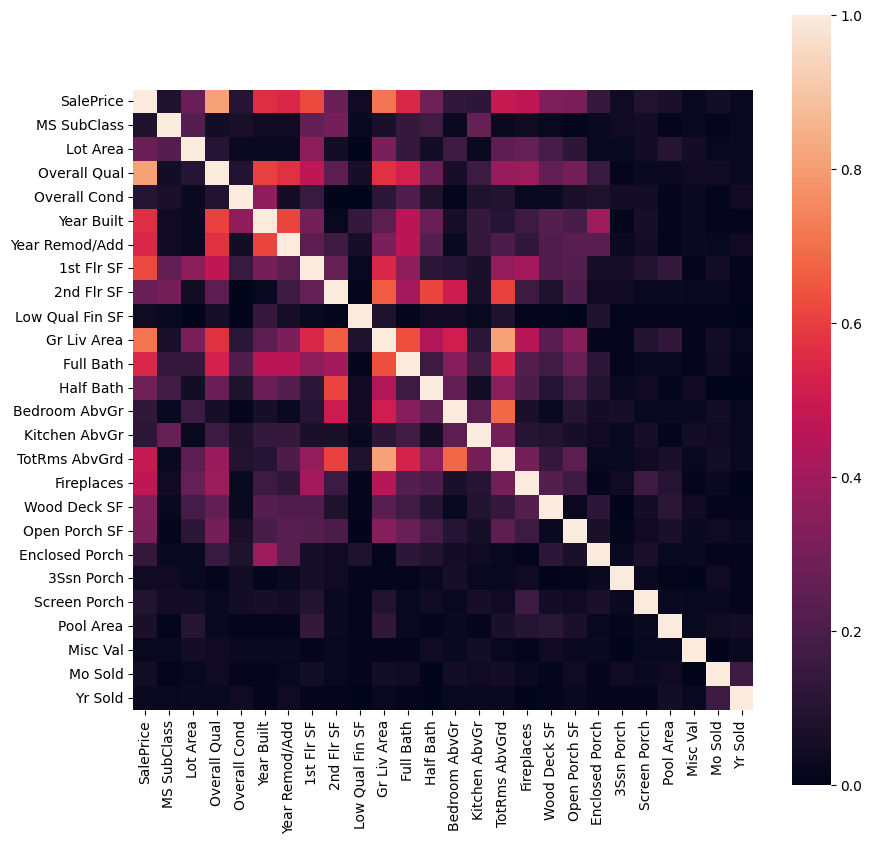

In [312]:
# Correlation plot - target and features
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;



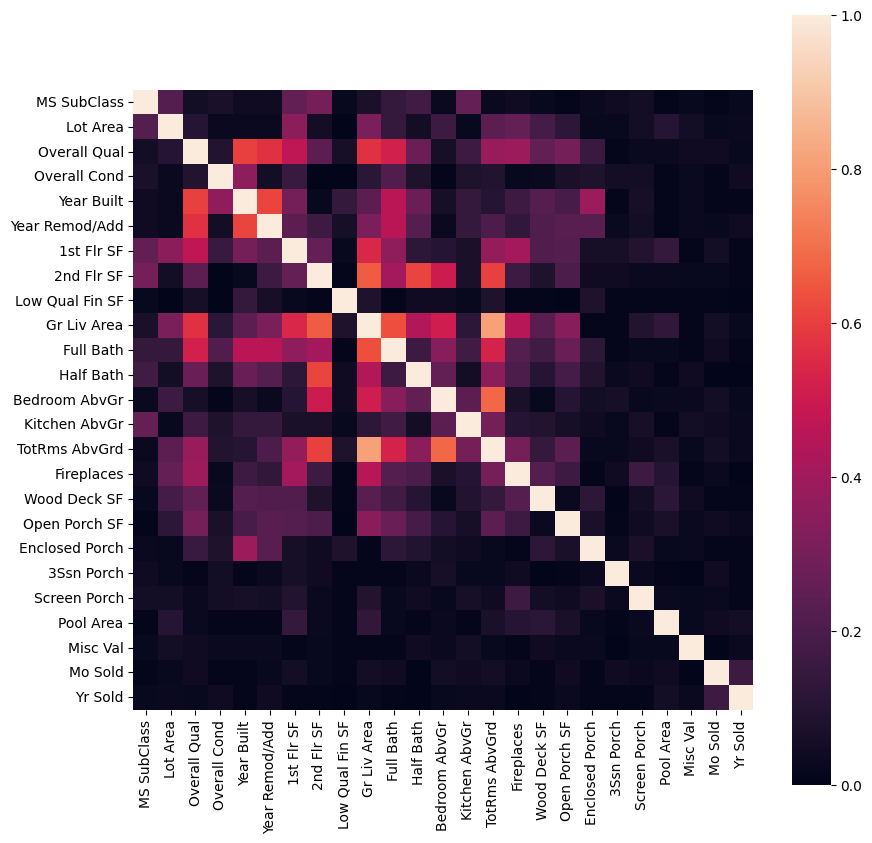

In [313]:
# Correlation plot - features only
plt.figure(figsize=(10,10))
correlation_matrix = df.drop( columns = [target_col] ).corr().abs().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True) ;



In [314]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Overall Qual,0.81
Gr Liv Area,0.71
1st Flr SF,0.62
Year Built,0.56
Year Remod/Add,0.54
Full Bath,0.54
TotRms AbvGrd,0.49
Fireplaces,0.47
Wood Deck SF,0.32


<Axes: >

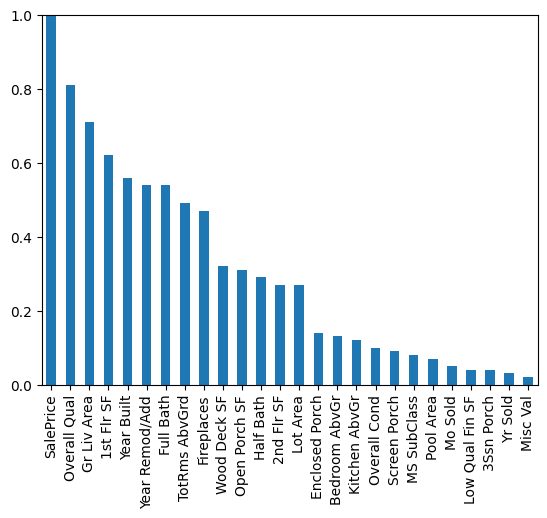

In [315]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])

In [316]:
corrs_int = df.corr().round(2).unstack().abs()
corrs_int.reset_index()

,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,MS SubClass,0.08
2,SalePrice,Lot Area,0.27
3,SalePrice,Overall Qual,0.81
4,SalePrice,Overall Cond,0.10
...,...,...,...
671,Yr Sold,Screen Porch,0.01
672,Yr Sold,Pool Area,0.05
673,Yr Sold,Misc Val,0.03
674,Yr Sold,Mo Sold,0.16


In [317]:
corrs_int = corrs_int[corrs_int < 1]
corrs_int.reset_index()

,level_0,level_1,0
0,SalePrice,MS SubClass,0.08
1,SalePrice,Lot Area,0.27
2,SalePrice,Overall Qual,0.81
3,SalePrice,Overall Cond,0.10
4,SalePrice,Year Built,0.56
...,...,...,...
645,Yr Sold,3Ssn Porch,0.01
646,Yr Sold,Screen Porch,0.01
647,Yr Sold,Pool Area,0.05
648,Yr Sold,Misc Val,0.03


In [318]:
corrs_int.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Overall Qual,SalePrice,0.81
1,TotRms AbvGrd,Gr Liv Area,0.81
2,Gr Liv Area,TotRms AbvGrd,0.81
3,SalePrice,Overall Qual,0.81
4,Gr Liv Area,SalePrice,0.71
...,...,...,...
645,Overall Cond,2nd Flr SF,0.00
646,Overall Cond,Low Qual Fin SF,0.00
647,Misc Val,3Ssn Porch,0.00
648,Misc Val,Mo Sold,0.00


In [319]:
corrs_int.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Overall Qual,SalePrice,0.81
1,Gr Liv Area,TotRms AbvGrd,0.81
2,Gr Liv Area,SalePrice,0.71
3,TotRms AbvGrd,Bedroom AbvGr,0.68
4,2nd Flr SF,Gr Liv Area,0.66
...,...,...,...
320,Low Qual Fin SF,Yr Sold,0.00
321,2nd Flr SF,Overall Cond,0.00
322,Low Qual Fin SF,Open Porch SF,0.00
323,Overall Cond,Low Qual Fin SF,0.00


### What do we notice?

- SalePrice correlated with General living area, first floor sf, year built, and overall quality
- lattice pattern: typically, if a feature doesn't correlate with other features, it also doesn't correlate with the target

In [320]:
df.size

68562

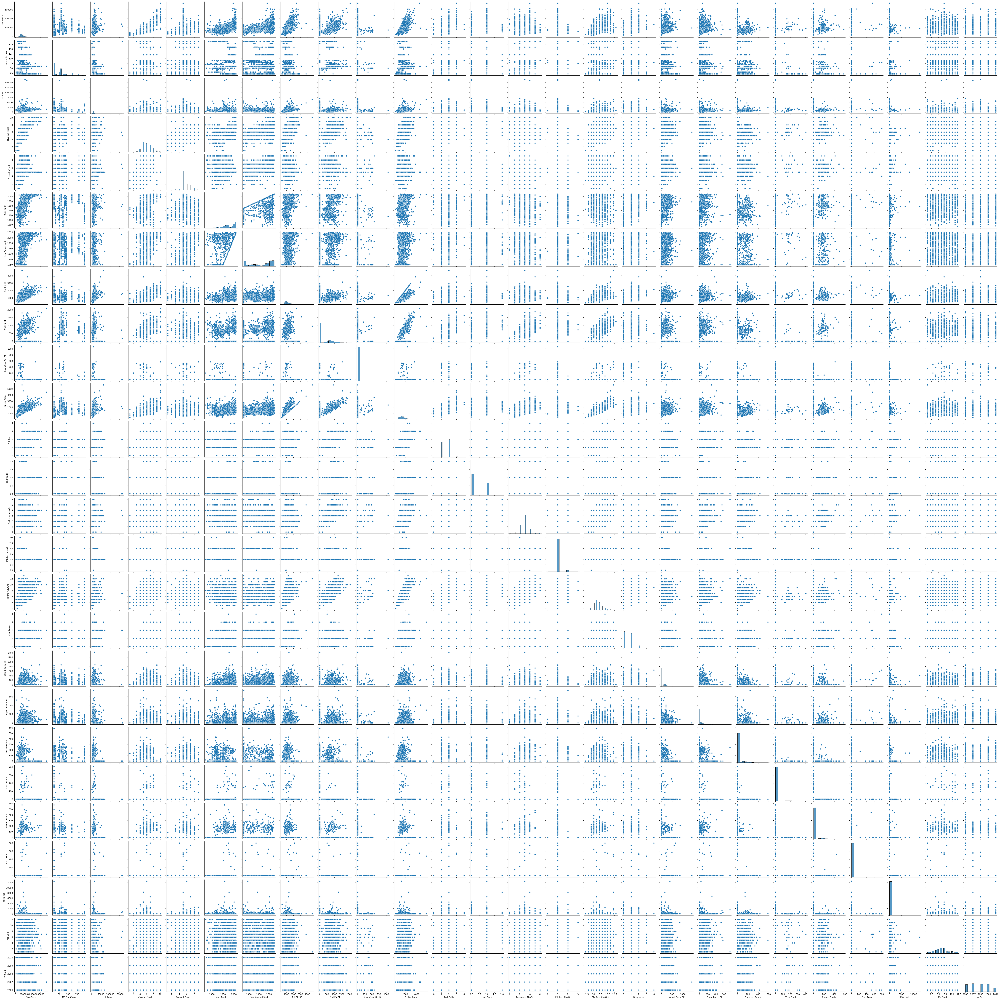

In [321]:
# Let's plot a pairplot
sns.pairplot(df) ;



### What do we notice?

- Not as many non-categorical scatter plots
- some linear-looking trends, including general living area and overall quality (i.e., they highly correlate with the target, and have linear-looking plot clustering)

In [322]:
# backup
df_int_bak2 = df_int.copy()

In [323]:
# restore
df_int = df_int_bak2.copy()

In [324]:
# update
df_int = df.copy()

### EDA — Object

In [325]:
# set df to df_object
df = df_object.copy()

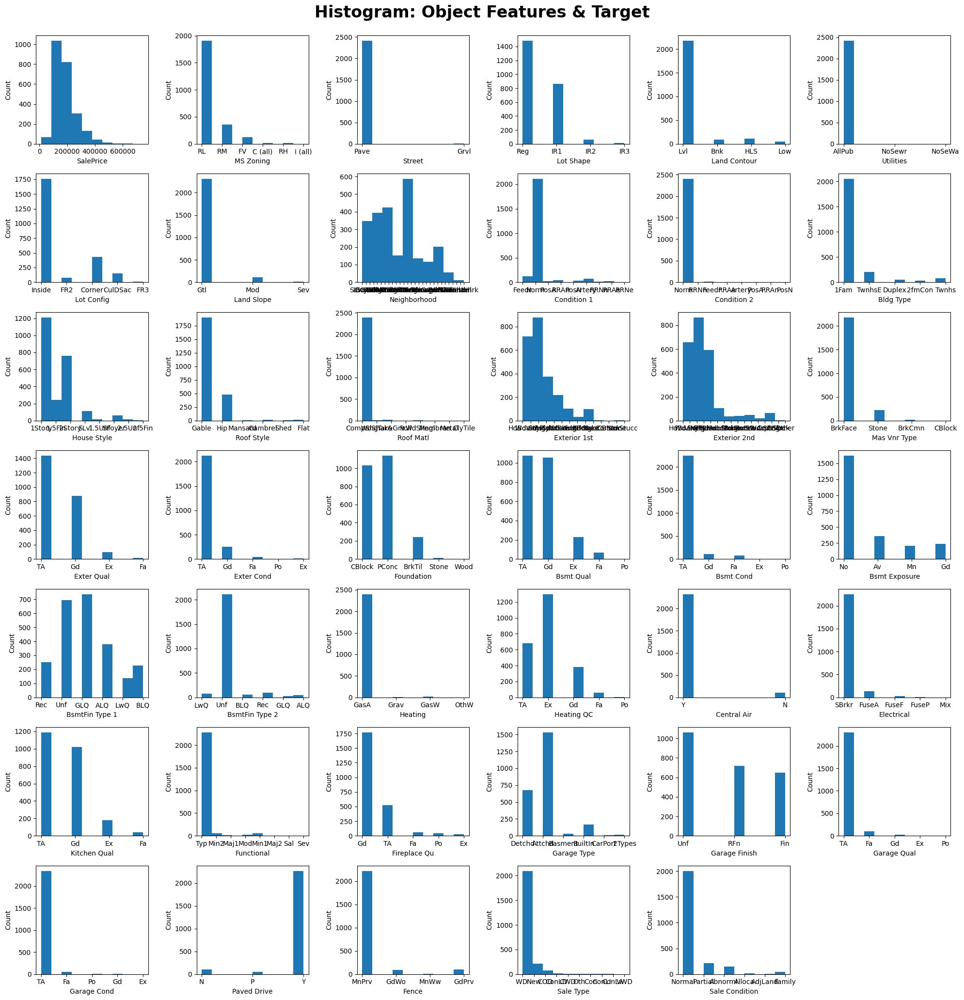

In [326]:
# Plot SalePrice and all of our predictors (features)

# parameterize plot settings
num_cols = 6
num_features = len(df.columns)
num_rows = num_features // num_cols + 1
plot_width = 20
plot_height = 3 * num_rows
column_names = df.columns
hist_y_label = "Count"

# assemble subplot canvas (subplots array)
fig, axs = plt.subplots(num_rows ,num_cols, figsize=(plot_width, plot_height))

# fill subplots
subplots = axs.flatten()
for n, column_name in enumerate(column_names): # Loop through rows
    subplots[n].hist(df[column_name])
    subplots[n].set_xlabel(column_name)
    subplots[n].set_ylabel(hist_y_label)

# hide empty subplots
for i in range(num_features, len(subplots)):
    fig.delaxes(subplots[i])

# format and show
plt.suptitle("Histogram: Object Features & Target", fontsize=24, weight="bold")
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.show()

### What do we notice?

- A few of the features — Exterior 1st, Exterior 2nd, House Style, and perhaps Neighborhood — all appear to trend with SalePrice, with all resembling positively-skewed normal distributions
- Perhaps some outliers in the columns

#### Next, we encode the object features in order to look at correlations:

In [327]:
# Assign numerical values and store in another column
df_encoded = pd.DataFrame(df[target_col])
for feature in feature_cols:
  df_feature = pd.get_dummies(
      pd.DataFrame(df[feature]),
      columns=[feature],
      prefix=feature,
      prefix_sep="_",
      dtype="int"
      )

  df_encoded = pd.concat([df_encoded, df_feature], axis=1, ignore_index=False)

df_encoded

,SalePrice,MS Zoning_C (all),MS Zoning_FV,MS Zoning_I (all),MS Zoning_RH,MS Zoning_RL,MS Zoning_RM,Street_Grvl,Street_Pave,Lot Shape_IR1,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,115400,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2,141000,0,0,0,0,0,1,0,1,0,...,0,0,0,1,0,0,0,0,1,0
3,254000,0,1,0,0,0,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
4,155000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
5,125000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,0,0,0,0,0,1,0,1,0,...,0,0,0,1,0,0,0,0,1,0
2633,162000,0,0,0,0,1,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
2634,211500,0,0,0,0,1,0,0,1,1,...,0,0,0,1,0,0,0,0,1,0
2635,165000,0,0,0,0,1,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0


In [328]:
# backup 4
df_o_bak4 = df.copy()

In [329]:
# restore from backup 4
df = df_o_bak4.copy()

In [330]:
df

,SalePrice,MS Zoning,Street,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,...,Functional,Fireplace Qu,Garage Type,Garage Finish,Garage Qual,Garage Cond,Paved Drive,Fence,Sale Type,Sale Condition
0,115400,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,Feedr,...,Typ,Gd,Detchd,Unf,TA,TA,N,MnPrv,WD,Normal
2,141000,RM,Pave,Reg,Bnk,AllPub,Inside,Gtl,IDOTRR,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,P,MnPrv,WD,Normal
3,254000,FV,Pave,IR1,Lvl,AllPub,Inside,Gtl,Somerst,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal
4,155000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,Feedr,...,Typ,Gd,Detchd,RFn,TA,TA,Y,MnPrv,WD,Normal
5,125000,RL,Pave,Reg,Lvl,AllPub,FR2,Gtl,Sawyer,Feedr,...,Typ,Fa,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,RM,Pave,Reg,Lvl,AllPub,Inside,Gtl,BrkSide,Norm,...,Typ,Gd,Detchd,Unf,TA,TA,Y,MnPrv,WD,Normal
2633,162000,RL,Pave,IR1,Lvl,AllPub,Inside,Gtl,SawyerW,Feedr,...,Typ,Gd,Attchd,Unf,TA,TA,Y,MnPrv,WD,Normal
2634,211500,RL,Pave,IR1,Lvl,AllPub,CulDSac,Gtl,Greens,Norm,...,Typ,TA,Attchd,Fin,TA,TA,Y,MnPrv,WD,Normal
2635,165000,RL,Pave,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,Typ,TA,Attchd,RFn,TA,TA,Y,MnPrv,WD,Normal


In [331]:
# update df
df = df_encoded.copy()

Correlation Matrices

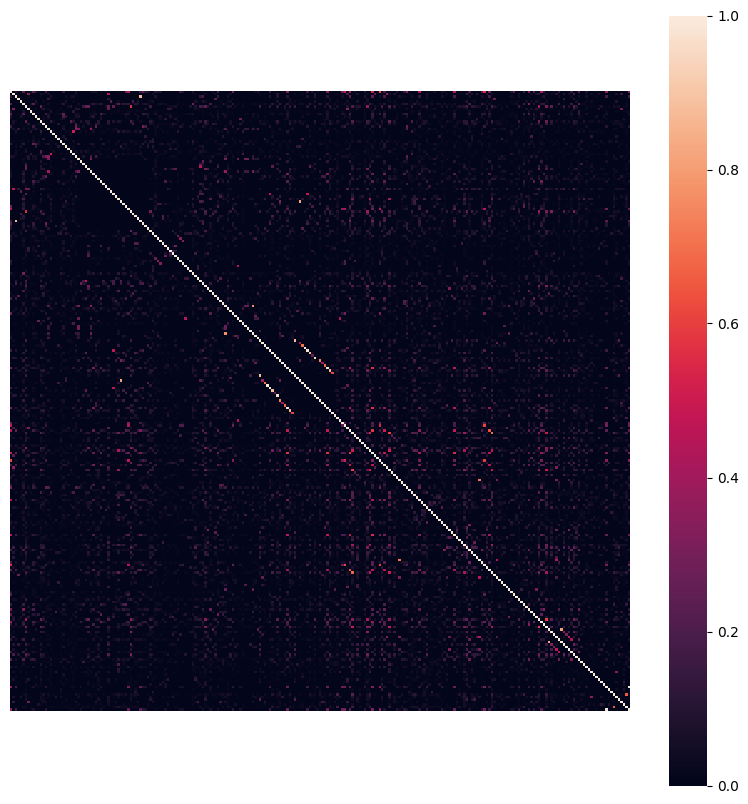

In [332]:
# Let's take a look at a correlation plot
plt.figure(figsize=(10,10))
correlation_matrix = df.corr().round(2)
sns.heatmap(data=correlation_matrix, annot=False, vmin=0, vmax=1, square=True, xticklabels=False, yticklabels=False) ;



In [333]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False)

,SalePrice
SalePrice,1.00
Bsmt Qual_Ex,0.61
Exter Qual_TA,0.60
Kitchen Qual_Ex,0.56
Kitchen Qual_TA,0.54
...,...
Condition 2_RRAe,0.00
Exterior 2nd_BrkFace,0.00
Roof Style_Shed,0.00
Bsmt Exposure_Mn,0.00


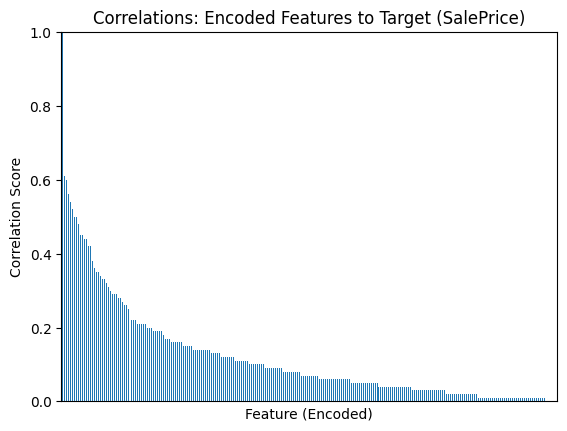

In [334]:
correlation_matrix = df.corr().round(2)
correlation_matrix[target_col].abs().sort_values(ascending=False).plot( kind="bar", ylim = [0,1])
plt.xticks([])
plt.title("Correlations: Encoded Features to Target (SalePrice)")
plt.xlabel('Feature (Encoded)')
plt.ylabel("Correlation Score") ;

In [335]:
corrs_object = df.corr().round(2).unstack().abs()
corrs_object.reset_index()

,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,MS Zoning_C (all),0.10
2,SalePrice,MS Zoning_FV,0.10
3,SalePrice,MS Zoning_I (all),0.02
4,SalePrice,MS Zoning_RH,0.05
...,...,...,...
61996,Sale Condition_Partial,Sale Condition_AdjLand,0.01
61997,Sale Condition_Partial,Sale Condition_Alloca,0.02
61998,Sale Condition_Partial,Sale Condition_Family,0.04
61999,Sale Condition_Partial,Sale Condition_Normal,0.68


In [336]:
corrs_object = corrs_object[corrs_object < 1]
corrs_object.reset_index()

,level_0,level_1,0
0,SalePrice,MS Zoning_C (all),0.10
1,SalePrice,MS Zoning_FV,0.10
2,SalePrice,MS Zoning_I (all),0.02
3,SalePrice,MS Zoning_RH,0.05
4,SalePrice,MS Zoning_RL,0.23
...,...,...,...
61741,Sale Condition_Partial,Sale Condition_Abnorml,0.08
61742,Sale Condition_Partial,Sale Condition_AdjLand,0.01
61743,Sale Condition_Partial,Sale Condition_Alloca,0.02
61744,Sale Condition_Partial,Sale Condition_Family,0.04


In [337]:
corrs_object.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Exterior 1st_VinylSd,Exterior 2nd_VinylSd,0.98
1,Sale Condition_Partial,Sale Type_New,0.98
2,Exterior 2nd_CmentBd,Exterior 1st_CemntBd,0.98
3,Exterior 2nd_VinylSd,Exterior 1st_VinylSd,0.98
4,Exterior 1st_CemntBd,Exterior 2nd_CmentBd,0.98
...,...,...,...
61741,Condition 2_Norm,Roof Matl_ClyTile,0.00
61742,Roof Matl_WdShake,Exterior 2nd_CBlock,0.00
61743,Roof Matl_WdShake,Exterior 2nd_HdBoard,0.00
61744,Roof Matl_WdShake,Exterior 2nd_ImStucc,0.00


In [338]:
corrs_object.sort_values(ascending = False)[::2].reset_index()

,level_0,level_1,0
0,Exterior 1st_VinylSd,Exterior 2nd_VinylSd,0.98
1,Exterior 2nd_CmentBd,Exterior 1st_CemntBd,0.98
2,Exterior 1st_CemntBd,Exterior 2nd_CmentBd,0.98
3,Exterior 1st_MetalSd,Exterior 2nd_MetalSd,0.97
4,Mas Vnr Type_BrkFace,Mas Vnr Type_Stone,0.95
...,...,...,...
30868,Lot Config_FR3,Functional_Maj2,0.00
30869,Lot Config_FR3,Functional_Sev,0.00
30870,Lot Config_FR3,Garage Qual_Po,0.00
30871,Roof Matl_WdShake,Exterior 2nd_CBlock,0.00


### What do we notice?

- After encoding, it is difficult to assess correlations visually among the different variables using a correlation matrix. To do this, we would likely need to cull redundant features and features poorly correlated with the target. However, given the large number of columns, it will still be difficult to prune the data by inspection.

- Hence, we devise a way to automate this process below.

In [339]:
# backup
df_object_bak2 = df_object.copy()

In [340]:
# restore
df_object = df_object_bak2.copy()

In [341]:
# update
df_object = df.copy()

## Processing



In [342]:
# backup
df_all_bak = df_all.copy()

In [346]:
# restore
df_all = df_all_bak.copy()

In [350]:
df_all = pd.concat([
    df_all[[target_col]],
    df_float.drop(columns=[target_col]),
    df_int.drop(columns=[target_col]),
    df_object.drop(columns=[target_col])
    ],
    axis = 1)

In [351]:
df_all

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,90000,72.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1967.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [353]:
df_all.isna().sum().sort_values(ascending=False)

,0
Sale Condition_Partial,211
Sale Condition_Normal,211
Sale Condition_Family,211
Sale Condition_Alloca,211
Sale Condition_AdjLand,211
...,...
3Ssn Porch,0
Enclosed Porch,0
Yr Sold,0
Mo Sold,0


In [354]:
df_all.dropna()

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
5,125000,70.0,0.0,842.0,0.0,70.0,912.0,0.0,0.0,1974.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [355]:
# backup
df_all_bak2 = df_all.copy()

In [356]:
# restore
df_all = df_all_bak2.copy()

In [357]:
df_all = df_all.dropna()

### Feature Selection

In [358]:
df = df_all.copy()

In [359]:
corrs = df.corr().round(2).unstack().abs()
corrs.reset_index()

,level_0,level_1,0
0,SalePrice,SalePrice,1.00
1,SalePrice,Lot Frontage,0.35
2,SalePrice,Mas Vnr Area,0.50
3,SalePrice,BsmtFin SF 1,0.41
4,SalePrice,BsmtFin SF 2,0.01
...,...,...,...
81220,Sale Condition_Partial,Sale Condition_AdjLand,0.01
81221,Sale Condition_Partial,Sale Condition_Alloca,0.02
81222,Sale Condition_Partial,Sale Condition_Family,0.04
81223,Sale Condition_Partial,Sale Condition_Normal,0.68


In [360]:
corrs = corrs[corrs < 1]
corrs.reset_index()

,level_0,level_1,0
0,SalePrice,Lot Frontage,0.35
1,SalePrice,Mas Vnr Area,0.50
2,SalePrice,BsmtFin SF 1,0.41
3,SalePrice,BsmtFin SF 2,0.01
4,SalePrice,Bsmt Unf SF,0.15
...,...,...,...
80929,Sale Condition_Partial,Sale Condition_Abnorml,0.08
80930,Sale Condition_Partial,Sale Condition_AdjLand,0.01
80931,Sale Condition_Partial,Sale Condition_Alloca,0.02
80932,Sale Condition_Partial,Sale Condition_Family,0.04


In [361]:
corrs.sort_values(ascending = False).reset_index()

,level_0,level_1,0
0,Exterior 2nd_VinylSd,Exterior 1st_VinylSd,0.98
1,Exterior 1st_CemntBd,Exterior 2nd_CmentBd,0.98
2,Sale Condition_Partial,Sale Type_New,0.98
3,Exterior 2nd_CmentBd,Exterior 1st_CemntBd,0.98
4,Sale Type_New,Sale Condition_Partial,0.98
...,...,...,...
80929,Kitchen Qual_Gd,Roof Matl_CompShg,0.00
80930,Kitchen Qual_Gd,Roof Style_Shed,0.00
80931,Kitchen Qual_Gd,Roof Style_Mansard,0.00
80932,Kitchen Qual_Gd,Exterior 1st_Stone,0.00


In [362]:
corrs_list_half = []
for level_0, level_1 in corrs.index:
  if (level_1, level_0) not in corrs_list_half:
    corrs_list_half.append((level_0, level_1))

corrs_list_half[:10]

[('SalePrice', 'Lot Frontage'),
 ('SalePrice', 'Mas Vnr Area'),
 ('SalePrice', 'BsmtFin SF 1'),
 ('SalePrice', 'BsmtFin SF 2'),
 ('SalePrice', 'Bsmt Unf SF'),
 ('SalePrice', 'Total Bsmt SF'),
 ('SalePrice', 'Bsmt Full Bath'),
 ('SalePrice', 'Bsmt Half Bath'),
 ('SalePrice', 'Garage Yr Blt'),
 ('SalePrice', 'Garage Cars')]

In [363]:
len(corrs_list_half)

40467

In [364]:
corrs[corrs_list_half].sort_values(ascending=False)

Exterior 1st_VinylSd  Exterior 2nd_VinylSd      0.98
Exterior 1st_CemntBd  Exterior 2nd_CmentBd      0.98
Sale Type_New         Sale Condition_Partial    0.98
Exterior 1st_MetalSd  Exterior 2nd_MetalSd      0.97
Mas Vnr Type_BrkFace  Mas Vnr Type_Stone        0.95
                                                ... 
Misc Val              Kitchen Qual_Gd           0.00
                      Electrical_Mix            0.00
                      Electrical_FuseP          0.00
Sale Type_VWD         Sale Condition_Family     0.00
                      Sale Condition_Alloca     0.00
Length: 40467, dtype: float64

In [365]:
corrs_list_half_bak = corrs_list_half.copy()

In [366]:
corrs_list_half = corrs_list_half_bak.copy()

In [369]:
throwaways_hi = set()
throwaways_lo = set()
threshold_hi = 0.8
threshold_lo = 0.05
for index_pair in corrs_list_half:
  l0 = index_pair[0]
  l1 = index_pair[1]

  if (l0 != target_col and l1 != target_col):
    if corrs[index_pair] >= threshold_hi:

      c0 = corrs[(target_col, l0)]
      c1 = corrs[(target_col, l1)]
      throwaways_hi.add(l0 if c0 < c1 else l1)
  else:
    if corrs[index_pair] < threshold_lo:
      throwaways_lo.add(l0 if l1 == target_col else l1)


In [370]:
throwaways_hi

{'1st Flr SF',
 'BsmtFin SF 2',
 'Electrical_FuseA',
 'Exter Cond_Gd',
 'Exter Qual_Gd',
 'Exterior 2nd_AsbShng',
 'Exterior 2nd_Brk Cmn',
 'Exterior 2nd_CmentBd',
 'Exterior 2nd_HdBoard',
 'Exterior 2nd_MetalSd',
 'Exterior 2nd_VinylSd',
 'Exterior 2nd_Wd Sdng',
 'Fireplace Qu_TA',
 'Foundation_CBlock',
 'Garage Area',
 'Garage Cond_Ex',
 'Garage Cond_Fa',
 'Garage Qual_TA',
 'Garage Type_Attchd',
 'Garage Yr Blt',
 'Heating_GasW',
 'House Style_1Story',
 'House Style_2Story',
 'Kitchen Qual_Gd',
 'Land Slope_Mod',
 'Lot Shape_IR1',
 'MS SubClass',
 'MS Zoning_FV',
 'MS Zoning_RL',
 'Mas Vnr Type_BrkFace',
 'Paved Drive_N',
 'Roof Style_Gable',
 'Sale Condition_Partial',
 'TotRms AbvGrd'}

In [371]:
throwaways_lo

{'3Ssn Porch',
 'Bldg Type_TwnhsE',
 'Bsmt Cond_Ex',
 'Bsmt Cond_Po',
 'Bsmt Cond_TA',
 'Bsmt Exposure_Mn',
 'Bsmt Qual_Po',
 'BsmtFin SF 2',
 'BsmtFin Type 2_ALQ',
 'Condition 1_RRAn',
 'Condition 1_RRNe',
 'Condition 1_RRNn',
 'Condition 2_Artery',
 'Condition 2_Feedr',
 'Condition 2_Norm',
 'Condition 2_RRAe',
 'Condition 2_RRAn',
 'Condition 2_RRNn',
 'Electrical_Mix',
 'Exter Cond_Po',
 'Exterior 1st_BrkComm',
 'Exterior 1st_BrkFace',
 'Exterior 1st_CBlock',
 'Exterior 1st_ImStucc',
 'Exterior 1st_Stone',
 'Exterior 1st_Stucco',
 'Exterior 1st_WdShing',
 'Exterior 2nd_AsphShn',
 'Exterior 2nd_BrkFace',
 'Exterior 2nd_CBlock',
 'Exterior 2nd_Other',
 'Exterior 2nd_Stone',
 'Exterior 2nd_Stucco',
 'Fence_GdPrv',
 'Fence_MnWw',
 'Fireplace Qu_Fa',
 'Foundation_Stone',
 'Foundation_Wood',
 'Functional_Maj1',
 'Functional_Min1',
 'Functional_Mod',
 'Functional_Sal',
 'Functional_Sev',
 'Garage Cond_Ex',
 'Garage Cond_Gd',
 'Garage Qual_Ex',
 'Garage Qual_Gd',
 'Garage Type_2Types',
 'H

In [372]:
feature_cols_all_drop_noise = list(throwaways_lo)
feature_cols_all_drop_redundant = list(throwaways_hi)

In [373]:
feature_cols_all_drop = feature_cols_all_drop_noise + feature_cols_all_drop_redundant + [target_col]
feature_cols_all_drop

['Mas Vnr Type_BrkCmn',
 'Exterior 2nd_CBlock',
 'Exterior 2nd_BrkFace',
 'Lot Config_FR3',
 'Lot Config_FR2',
 'House Style_1Story',
 'Garage Qual_Gd',
 'BsmtFin SF 2',
 'Neighborhood_GrnHill',
 'House Style_2.5Fin',
 'Exterior 2nd_Stucco',
 'Fireplace Qu_Fa',
 'Heating_OthW',
 'House Style_2.5Unf',
 'Functional_Sev',
 'Neighborhood_ClearCr',
 'Sale Type_Con',
 'Heating_Grav',
 'Roof Matl_Tar&Grv',
 'Condition 1_RRAn',
 '3Ssn Porch',
 'Neighborhood_Landmrk',
 'Utilities_AllPub',
 'Garage Qual_Ex',
 'Condition 1_RRNe',
 'Fence_GdPrv',
 'Sale Type_ConLI',
 'Sale Type_Oth',
 'Functional_Min1',
 'Exterior 1st_Stone',
 'Exterior 2nd_Other',
 'Functional_Mod',
 'Yr Sold',
 'Land Contour_Low',
 'Neighborhood_SawyerW',
 'Exter Cond_Po',
 'Sale Type_ConLw',
 'Garage Cond_Gd',
 'Garage Cond_Ex',
 'Neighborhood_NWAmes',
 'Bsmt Cond_Po',
 'Sale Type_CWD',
 'Lot Config_Corner',
 'Sale Condition_Alloca',
 'Exterior 1st_CBlock',
 'Neighborhood_Blueste',
 'Roof Matl_Roll',
 'BsmtFin Type 2_ALQ',
 'Bs

In [374]:
feature_cols_all = list( df.drop( columns = feature_cols_all_drop ) )
target_col, feature_cols_all, feature_cols_all_drop

('SalePrice',
 ['Lot Frontage',
  'Mas Vnr Area',
  'BsmtFin SF 1',
  'Bsmt Unf SF',
  'Total Bsmt SF',
  'Bsmt Full Bath',
  'Bsmt Half Bath',
  'Garage Cars',
  'Lot Area',
  'Overall Qual',
  'Overall Cond',
  'Year Built',
  'Year Remod/Add',
  '2nd Flr SF',
  'Gr Liv Area',
  'Full Bath',
  'Half Bath',
  'Bedroom AbvGr',
  'Kitchen AbvGr',
  'Fireplaces',
  'Wood Deck SF',
  'Open Porch SF',
  'Enclosed Porch',
  'Screen Porch',
  'Pool Area',
  'Mo Sold',
  'MS Zoning_C (all)',
  'MS Zoning_RH',
  'MS Zoning_RM',
  'Street_Grvl',
  'Street_Pave',
  'Lot Shape_IR2',
  'Lot Shape_Reg',
  'Land Contour_Bnk',
  'Land Contour_HLS',
  'Land Contour_Lvl',
  'Lot Config_CulDSac',
  'Lot Config_Inside',
  'Land Slope_Gtl',
  'Neighborhood_BrDale',
  'Neighborhood_BrkSide',
  'Neighborhood_CollgCr',
  'Neighborhood_Crawfor',
  'Neighborhood_Edwards',
  'Neighborhood_IDOTRR',
  'Neighborhood_MeadowV',
  'Neighborhood_Mitchel',
  'Neighborhood_NAmes',
  'Neighborhood_NPkVill',
  'Neighborho

In [377]:
# Split data frame into target and features
target        = df[target_col].copy()
features_all  = df[feature_cols_all].copy()

In [378]:
# Verify features
features_all

,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Cars,Lot Area,Overall Qual,...,Fence_GdWo,Fence_MnPrv,Sale Type_COD,Sale Type_ConLD,Sale Type_New,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Family,Sale Condition_Normal
0,62.0,0.0,513.0,348.0,1005.0,1.0,0.0,2.0,14299,4,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,50.0,0.0,0.0,780.0,780.0,0.0,0.0,1.0,9000,6,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,68.0,0.0,484.0,491.0,975.0,1.0,0.0,2.0,7379,8,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,60.0,0.0,350.0,0.0,560.0,1.0,0.0,2.0,7200,7,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
5,70.0,0.0,842.0,70.0,912.0,0.0,0.0,1.0,8521,5,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,52.0,0.0,0.0,816.0,816.0,0.0,0.0,2.0,6240,6,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2633,74.0,0.0,460.0,308.0,1054.0,1.0,0.0,2.0,10778,7,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2634,61.0,0.0,960.0,266.0,1226.0,1.0,0.0,2.0,3782,8,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2635,78.0,174.0,0.0,1064.0,1064.0,0.0,0.0,2.0,10140,6,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [379]:
# Verify target
target

,SalePrice
0,115400
2,141000
3,254000
4,155000
5,125000
...,...
2632,114500
2633,162000
2634,211500
2635,165000


In [380]:
type(features_all), features_all.shape, features_all.ndim

(pandas.core.frame.DataFrame, (2404, 159), 2)

In [381]:
type(target), target.shape, target.ndim

(pandas.core.series.Series, (2404,), 1)

In [382]:
# backup 5
df_bak5 = df.copy()

In [383]:
# restore from backup 5
df = df_bak5.copy()

In [384]:
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Yr Blt,...,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,115400,62.0,0.0,513.0,144.0,348.0,1005.0,1.0,0.0,1964.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2,141000,50.0,0.0,0.0,0.0,780.0,780.0,0.0,0.0,1979.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,254000,68.0,0.0,484.0,0.0,491.0,975.0,1.0,0.0,2000.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4,155000,60.0,0.0,350.0,210.0,0.0,560.0,1.0,0.0,1971.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
5,125000,70.0,0.0,842.0,0.0,70.0,912.0,0.0,0.0,1974.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,0.0,816.0,816.0,0.0,0.0,1985.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2633,162000,74.0,0.0,460.0,286.0,308.0,1054.0,1.0,0.0,1990.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2634,211500,61.0,0.0,960.0,0.0,266.0,1226.0,1.0,0.0,1981.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
2635,165000,78.0,174.0,0.0,0.0,1064.0,1064.0,0.0,0.0,1974.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


In [386]:
# Execute the selection
df = pd.concat([target, features_all], axis=1)
df

,SalePrice,Lot Frontage,Mas Vnr Area,BsmtFin SF 1,Bsmt Unf SF,Total Bsmt SF,Bsmt Full Bath,Bsmt Half Bath,Garage Cars,Lot Area,...,Fence_GdWo,Fence_MnPrv,Sale Type_COD,Sale Type_ConLD,Sale Type_New,Sale Type_WD,Sale Condition_Abnorml,Sale Condition_AdjLand,Sale Condition_Family,Sale Condition_Normal
0,115400,62.0,0.0,513.0,348.0,1005.0,1.0,0.0,2.0,14299,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2,141000,50.0,0.0,0.0,780.0,780.0,0.0,0.0,1.0,9000,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,254000,68.0,0.0,484.0,491.0,975.0,1.0,0.0,2.0,7379,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
4,155000,60.0,0.0,350.0,0.0,560.0,1.0,0.0,2.0,7200,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
5,125000,70.0,0.0,842.0,70.0,912.0,0.0,0.0,1.0,8521,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2632,114500,52.0,0.0,0.0,816.0,816.0,0.0,0.0,2.0,6240,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2633,162000,74.0,0.0,460.0,308.0,1054.0,1.0,0.0,2.0,10778,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2634,211500,61.0,0.0,960.0,266.0,1226.0,1.0,0.0,2.0,3782,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
2635,165000,78.0,174.0,0.0,1064.0,1064.0,0.0,0.0,2.0,10140,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


### Fit & Assess Our Model

#### Linear Regression — Sklearn

In [388]:
# define our features set
features = features_all

Now, we perform a linear regression using sklearn:

In [389]:
# First we run a single split (single holdout) to see what the data looks like:
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size = 0.2, random_state=42)

In [390]:
# Fit a linear model using Sklearn
model = LinearRegression()
model.fit(X_train, y_train)

( model.intercept_, model.coef_ )

(np.float64(-630220.7607865608),
 array([-5.83923413e+01,  1.07894188e+01,  4.11778973e-01, -9.54274396e+00,
         1.27669720e+01,  6.89718167e+03,  7.47355515e+02,  9.19633242e+03,
         1.81419663e-01,  8.16204124e+03,  5.08846902e+03,  2.23719384e+02,
         6.01699053e+01, -1.06316139e+01,  5.40346640e+01,  5.44408751e+03,
         1.66437781e+03, -2.96536842e+03, -1.09537860e+04,  5.41883670e+03,
         7.52351508e+00, -1.77445806e+01,  6.45988468e+00,  4.00332510e+01,
        -1.84216773e+01,  9.03576371e+01, -1.70783729e+04,  7.22253143e+03,
        -1.56709989e+03, -1.67330921e+04,  1.67330921e+04,  6.99058054e+03,
         6.02977491e+02, -8.32812533e+03,  1.06645301e+04,  4.14695071e+03,
         7.20187504e+03,  2.01177330e+03, -7.54261418e+03,  1.38595488e+04,
         1.05556414e+03,  3.47688908e+02,  1.76931097e+04, -1.45892213e+04,
        -2.18412537e+03,  1.46711677e+03, -3.64005502e+03, -4.55195399e+03,
         1.88447473e+04,  4.39065476e+04,  3.52871469e+

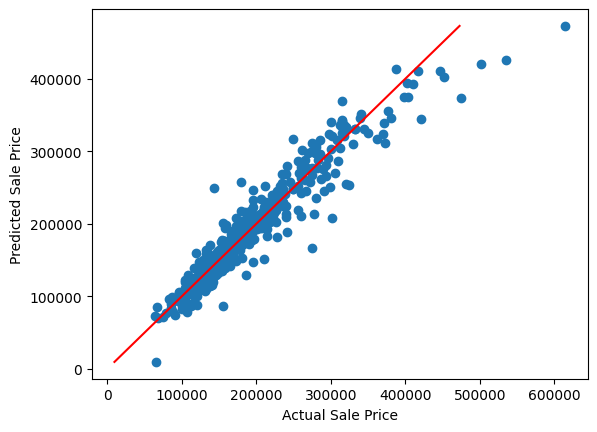

In [391]:
# See how well our model performs on our test data
y_pred = model.predict(X_test)
plt.scatter(y_test, y_pred)
plt.plot([min(y_pred), max(y_pred)],[min(y_pred), max(y_pred)], c='red')
plt.xlabel('Actual Sale Price')
plt.ylabel('Predicted Sale Price') ;

In [392]:
list(zip(y_test,y_pred))[:10]

[(152500, np.float64(174857.73491935537)),
 (373000, np.float64(311130.2833345799)),
 (123000, np.float64(136253.54071864323)),
 (128250, np.float64(142055.61346045043)),
 (215000, np.float64(216580.68288853718)),
 (143000, np.float64(248807.9320784117)),
 (132500, np.float64(141794.56891017954)),
 (133000, np.float64(109505.06976264727)),
 (421250, np.float64(344196.97898234276)),
 (207000, np.float64(212358.00667023123))]

We'll use RMSE as our performance metric.

In [393]:
# Calculate root mean squared error on test data
rmse = metrics.mean_squared_error(y_test, y_pred)**0.5
print(f"RMSE: {rmse}")

RMSE: 23364.476941403325


Evaluate using cross_val_score (Single CV):

In [394]:
# Use cross validation (k-fold) to assess model performance (Single CV — Single run of a K-Fold loop)
results_cvs = cross_val_score(model, features, target, scoring='neg_root_mean_squared_error', cv = 10)
rmse_cvs = abs(results_cvs.mean())
print(f"CV RMSE: {rmse_cvs}")

CV RMSE: 27146.16565023126


Evaulate using CV loop (Multiple CV):

In [395]:
# Multiple CV loop
n = 500
rmses = []
for i in range(0, n):

  # First we will break up our data into training and testing sets
  X_train, X_test, y_train, y_test = train_test_split(features, target, test_size = 0.2)

  # Fit a linear model using Sklearn
  my_fit_lr = LinearRegression()
  my_fit_lr.fit(X_train, y_train)

  # See how well our model performs on our test data
  y_pred = my_fit_lr.predict(X_test)

  # Capture performance metric (accuracy) in array
  rmses.append(metrics.mean_squared_error(y_test, y_pred)**0.5)

results = np.array(rmses)
results[:10]

array([25061.1704851 , 27726.06798494, 25044.40561809, 22507.89872941,
       25232.07694697, 29134.96374929, 37586.84812479, 30981.86356615,
       38760.80408179, 37450.95948191])

In [396]:
# Calculate mean of results
results.mean()

np.float64(28351.539646729183)

## Data Visualization/Communication of Results


### Residual Analysis

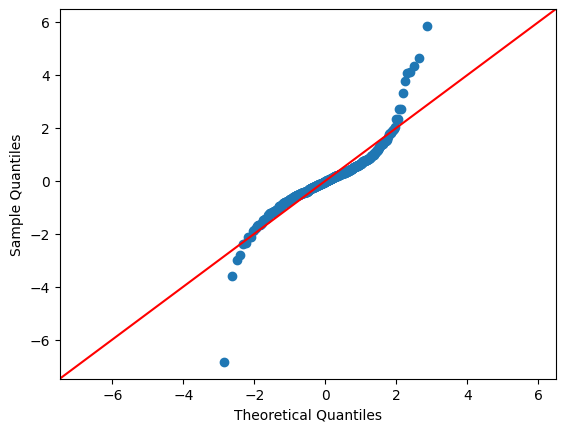

In [397]:
# QQ Plot - Residuals are normally distributed
res = y_test - y_pred
sm.qqplot(res, fit=True, line="45") ;

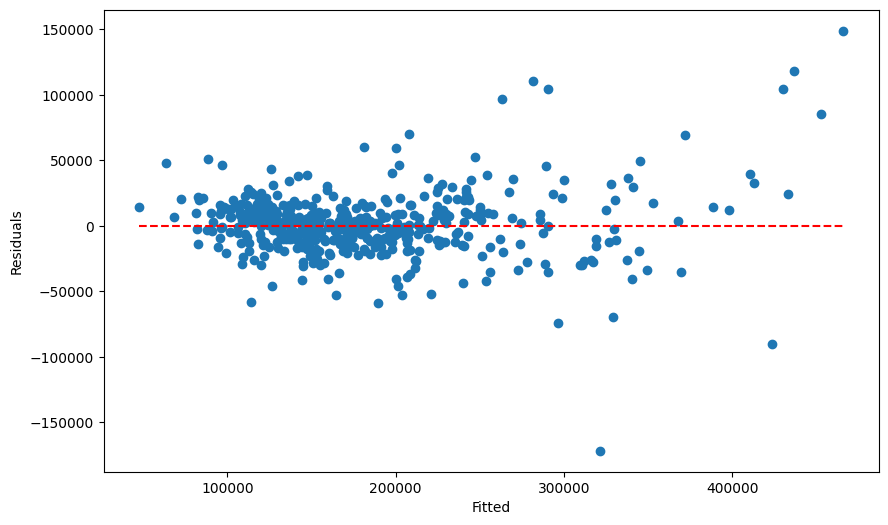

In [398]:
# Residuals vs Fitted (Predicted) Values - Constant variance
plt.figure(figsize = (10,6))
plt.scatter(y_pred, res)
plt.xlabel("Fitted")
plt.ylabel("Residuals")
plt.hlines(0, min(y_pred), max(y_pred), colors = 'red', linestyles = 'dashed') ;

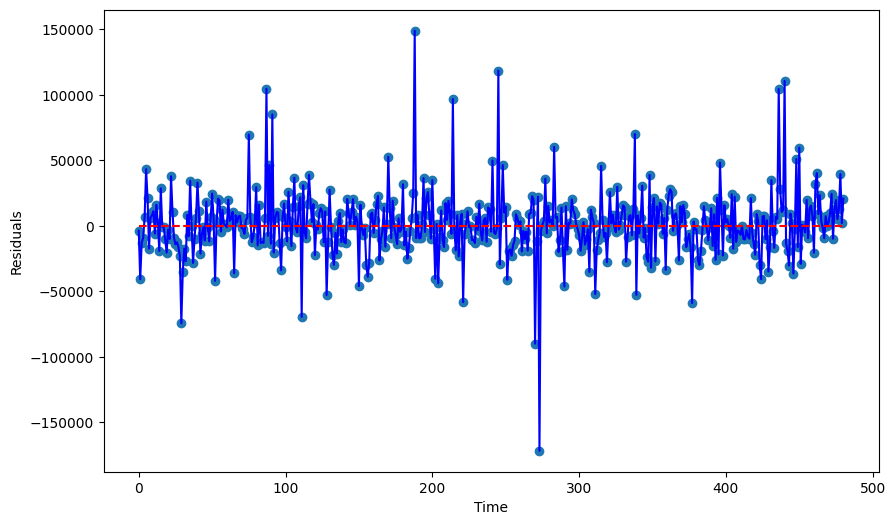

In [399]:
# Residuals vs Time - indepedence
plt.figure(figsize = (10,6))
plt.scatter(range(len(res)), res)
plt.plot(range(len(res)), res, 'b')
plt.xlabel("Time")
plt.ylabel("Residuals")
plt.hlines(0, min(range(len(res))), max(range(len(res))), colors = 'red', linestyles = 'dashed') ;

This result is a noticeable improvement over the previous passes: the rmse is lower (around 25000, about 5000-10000 lower than before), and the data points on the qq plot more closely keep to the line, at least disregarding the extremes. The residual analysis still shows some residuals data not conforming to a normal distribution, but most of the data seems to align with our predictions for the object qq plot. More work could be done to improve this result, such as combining the data from all three types, or trying out different models.